# <a id='toc1_'></a>[US-Iran Conflict: An Econometric Analysis](#toc0_)

By Alexander Thompson, BSc (Hons)

September 2026

**Table of contents**<a id='toc0_'></a>    
- [US-Iran Conflict: An Econometric Analysis](#toc1_)    
  - [About the Author](#toc1_1_)    
  - [Executive Summary](#toc1_2_)    
  - [Introduction](#toc1_3_)    
  - [Data Dictionary](#toc1_4_)    
  - [Data Engineering](#toc1_5_)    
    - [Extraction](#toc1_5_1_)    
    - [Transformation](#toc1_5_2_)    
      - [Timeline of Events](#toc1_5_2_1_)    
    - [Loading](#toc1_5_3_)    
  - [Econometric Analysis](#toc1_6_)    
    - [Regression of Brent Return](#toc1_6_1_)    
      - [Interpretation of the Coefficient Estimates of the Regression](#toc1_6_1_1_)    
      - [Hypothesis Tests for individual significance](#toc1_6_1_2_)    
        - [Escalation Two-tailed T-test](#toc1_6_1_2_1_)    
        - [Supply_Disruption Two-tailed T-test](#toc1_6_1_2_2_)    
        - [Deescalation Two-tailed T-test](#toc1_6_1_2_3_)    
    - [Goodness-of-fit](#toc1_6_2_)    
    - [White Test for Heteroscedasticity](#toc1_6_3_)    
    - [Breusch-Godfrey LM Test for AR(2) Correlation in the Residuals](#toc1_6_4_)    
    - [Durbin-Watson Test for Autocorrelation](#toc1_6_5_)    
    - [Jarque-Bera Test for Normality in the Residuals](#toc1_6_6_)    
    - [Tests for Multicollinearity](#toc1_6_7_)    
      - [Variance Inflation Factor](#toc1_6_7_1_)    
      - [Wald test of S&P 500 and VIX](#toc1_6_7_2_)    
    - [Chow Test for a Structural Break](#toc1_6_8_)    
    - [Significance of the conflict on Brent oil returns](#toc1_6_9_)    
    - [Effect of the US Dollar between pre-conflict and conflict periods](#toc1_6_10_)    
    - [Ramsey RESET Test for Misspecification](#toc1_6_11_)    
    - [Final Model Diagnostics](#toc1_6_12_)    
    - [Overall Conclusion](#toc1_6_13_)    
    - [Policy and Government Use](#toc1_6_14_)    
    - [Recommendations](#toc1_6_15_)    
    - [Practical Implications](#toc1_6_16_)    
  - [References](#toc1_7_)    
  - [Appendix](#toc1_8_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[About the Author](#toc0_)

**Alexander Thompson, BSc (Hons)** *is a data scientist and economics graduate specialising in financial markets, geopolitical risk analysis and time-series modelling. Combining a strong foundation in economic theory with advanced technical expertise in Python, machine learning and big data engineering, this project demonstrates a rigorous quantitative workflow, from live API data extraction to robust regression diagnostics and econometric modelling to evaluate complex economic shocks.*

* **Connect:** 
  * [LinkedIn](www.linkedin.com/in/alexander-thompson-25336b231)
  * [My Portfolio](https://github.com/A1ex-21/My_Portfolio)

## <a id='toc1_2_'></a>[Executive Summary](#toc0_)

The purpose of this analysis is to deliver a rigorous econometric investigation into the pricing dynamics and volatile behaviour of Brent crude oil returns under exogenous geopolitical shocks, specifically focusing on the US-Iran conflict. Automated Python-based data pipelines were combined with time series econometric modelling to deliver robust policy insights. The empirical results indicate that exogenous geopolitical shocks associated with the US-Iran conflict exert a measurable influence on Brent crude oil returns. Military escalation events are associated with statistically significant increases in Brent returns, while the estimated effects of supply disruptions and de-escalation events are not statistically significant. Notably, the relationship between the US Dollar and Brent returns undergoes a significant structural shift during active conflict periods. The interaction term, USD-Conflict reveals that market sensitivity to currency movements significantly intensifies when geopolitical risk is elevated, thereby demonstrating that currency hedging dynamics shift during wartime shocks. Risk managers and energy traders should abandon static currency hedges during geopolitical crises, adjusting exposures dynamically as US dollar sensitivity shifts during conflict phases. Furthermore, energy dependent firms should deploy pre-emptive hedging strategies rather than reacting to supply disruption shocks after they materialise.

* **Econometric & Diagnostic Rigor:** Models were formally validated to ensure unbiased inference, incorporating rigorous diagnostic checks including White's test for heteroscedasticity, Breusch-Godfrey and Durbin-Watson tests for high order serial correlation and residual normality testing. 
* **Structural Break & Dummy Modelling:** Utilised complex binary indicator modelling to isolate the distinct market impacts of military escalations, supply disruptions and de-escalation announcements in the Middle East.

## <a id='toc1_3_'></a>[Introduction](#toc0_)

The US-Iran conflict has had an immense impact on both geopolitics and the global economy through the military action in the Middle East and the following disruption of traffic via the Strait of Hormuz. This in turn has led to the crude oil markets and subsequent energy markets to experience substantial price volatility. The U.S. Energy Information Administration, the principal agency responsible for collecting, analysing and disseminating energy information, reported that Brent crude oil prices had risen sharply during the first quarter of 2026. This represented an increase from approximately \$61 per barrel to \$118 per barrel, the biggest increase on inflation-adjusted data going back to 1988. [(*Troderman and Keyserling, 2026*)](https://www.eia.gov/todayinenergy/detail.php?id=67424)

Crude oil is one of the most important commodities in the global economy today, with its price being highly sensitive to changes in its expected supply, demand and geopolitical risk. In major oil producing regions, such as the Middle East, both political and military instability have an immediate effect on the global oil and energy markets, particularly when these events threaten the production capacity or transportation routes of crude oil. The EIA, also reported that the price of crude oil increased more rapidly after the majority of the shipping traffic halted passing the Strait of Hormuz due to the risk of damage from Iranian attacks by the IRGC to tankers passing through the strait. [(*Troderman and Keyserling, 2026*)](https://www.eia.gov/todayinenergy/detail.php?id=67424). Due to this disruption, major oil producing countries such as Saudi Arabia, shut its oil production.

This analysis will be investigating whether the different types of developments during the conflict were statistically significantly associated with the daily Brent crude oil returns. Instead of treating all of the developments as equivalent to each other, they are divided into 3 categories, escalation, oil supply disruption and de-escalation. This allows us to observe whether the oil markets responded differently to any military escalation, events disrupting the supply of oil and its subsequent transportation and any events that reduced geopolitical uncertainty and supply risk.

For the analysis, a multiple linear regression model will be used for which the daily return on Brent crude oil is the dependent variable. The explanatory variables are three dummy variables representing the different types of developments during the conflict, daily change of USD, S&P 500, VIX and the previous day's Brent return. These are included as control variables to take into account for the broader financial-market movements and short-term persistence in oil returns.

**Objective:** To determine whether the coefficients on the development dummy variables is statistically significant to the daily returns of Brent crude oil.

Particular attention will be focused on whether these events that involve the direct threats to oil supply and its transportation are associated with greater changes in the Brent crude oil returns rather than other forms of escalation. These results will thereby be interpreted as statistical associations rather than just definitive causal effects due to the nature of oil prices to respond to other economic, financial and geopolitical developments that are not fully captured by the model.

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 \text{Escalation}_t + \beta_2 \text{SupplyDisruption}_t + \beta_3 \text{Deescalation}_t + \beta_4 r_{t}^{\text{USD}} + \beta_5 r_{t}^{\text{SP500}} + \beta_6 \Delta \text{VIX}_t + \beta_7 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

## <a id='toc1_4_'></a>[Data Dictionary](#toc0_)

| Variable | Type | Description | Construction / Measurement | Source |
|---|---|---|---|---|
| `date` | Date | Trading date for each observation. | Daily date index used to merge the market and event datasets. | FRED / EIA / manually compiled event chronology |
| `brent_price` | Continuous | Daily Brent crude oil spot price. | U.S. dollars per barrel. | EIA / FRED series `DCOILBRENTEU` |
| `brent_return` | Continuous | Daily percentage return on Brent crude oil. This is the dependent variable in the regression model. | `100 × [ln(brent_price_t) - ln(brent_price_t-1)]` | Constructed from `brent_price` |
| `escalation` | Dummy / Binary | Indicates whether a major U.S.–Iran conflict escalation event occurred on a given trading day. | `1` = escalation event; `0` = no escalation event. | Manually constructed from documented conflict-event dates |
| `supply_disruption` | Dummy / Binary | Indicates whether an event directly threatened or disrupted oil production, exports, shipping, infrastructure, or important transport routes such as the Strait of Hormuz. | `1` = supply-disruption event; `0` = no supply-disruption event. | Manually constructed from documented event dates |
| `deescalation` | Dummy / Binary | Indicates whether a significant de-escalation, diplomatic, ceasefire, or supply-restoration event occurred. | `1` = de-escalation event; `0` = no de-escalation event. | Manually constructed from documented event dates |
| `usd_index` | Continuous | Daily value of the Nominal Broad U.S. Dollar Index. | Index level. | FRED series `DTWEXBGS` |
| `usd_return` | Continuous | Daily percentage return on the U.S. dollar index. | `100 × [ln(usd_index_t) - ln(usd_index_t-1)]` | Constructed from `usd_index` |
| `sp500` | Continuous | Daily closing level of the S&P 500 Index. | Index closing level. | FRED series `SP500` |
| `sp500_return` | Continuous | Daily percentage return on the S&P 500. | `100 × [ln(sp500_t) - ln(sp500_t-1)]` | Constructed from `sp500` |
| `vix` | Continuous | Daily closing level of the CBOE Volatility Index. | VIX index level. | FRED series `VIXCLS` |
| `vix_change` | Continuous | Daily change in the VIX. | `vix_t - vix_t-1` | Constructed from `vix` |
| `brent_return_l1` | Continuous | One-day lag of the Brent crude oil return. Used to control for short-term persistence or reversal in oil-price movements. | `brent_return.shift(1)` | Constructed from `brent_return` |

## <a id='toc1_5_'></a>[Data Engineering](#toc0_)

Let's collect our continuous data from FRED using the FRED API.

In [1]:
import numpy as np
import pandas as pd
import requests
from functools import  reduce
import json
import os
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_white, acorr_breusch_godfrey, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

### <a id='toc1_5_1_'></a>[Extraction](#toc0_)

In [2]:
load_dotenv()

api_key = os.getenv("FRED_API_KEY")

def get_series(series_id, col_name):
    start = '2025-01-01'
    end = '2026-09-15'
    url = 'https://api.stlouisfed.org/fred/series/observations'
    params = {'series_id': series_id,
              'api_key': api_key,
              'file_type': 'json',
              'observation_start': start,
              'observation_end': end,
              'frequency': 'd'}
    r = requests.get(url, params=params)
    data = r.json()
    df = pd.DataFrame(data['observations'])
    df = df[['date', 'value']]
    df['date'] = pd.to_datetime(df['date'])
    df['value'] = pd.to_numeric(df['value'], errors='coerce')
    df = df.rename(columns={'value': col_name})
    return df

In [3]:
brent = get_series('DCOILBRENTEU', 'brent_price')
usd = get_series('DTWEXBGS', 'usd_index')
sp500 = get_series('SP500', 'sp500')
vix = get_series('VIXCLS', 'vix')

### <a id='toc1_5_2_'></a>[Transformation](#toc0_)

Now we must transform our data so it is ready for analysis, we will start by collating all the dataframes together into one coherent dataframe.

In [4]:
dfs = [brent, usd, sp500, vix]
df = reduce(lambda left, right: pd.merge(left, right, on='date', how='inner'), dfs)

In [5]:
df.head(5)

,date,brent_price,usd_index,sp500,vix
0,2025-01-01,NaN,NaN,NaN,NaN
1,2025-01-02,76.14,129.4598,5868.55,17.93
2,2025-01-03,76.72,129.4535,5942.47,16.13
3,2025-01-06,77.27,128.5380,5975.38,16.04
4,2025-01-07,77.84,128.6130,5909.03,17.82


The reason for the null values in our first row of observations is due to the 1st of January being a public and bank holiday and so no data is collected for that day. Therefore, we can remove the null values in the first row, but before doing so, let's check for any other null values.

In [6]:
df.isna().sum()

date            0
brent_price    14
usd_index      18
sp500          19
vix             5
dtype: int64

These null values are appropriate to drop as it is trading day data we are looking at.

In [7]:
df = df.dropna()

In [8]:
df.isna().sum()

date           0
brent_price    0
usd_index      0
sp500          0
vix            0
dtype: int64

In [9]:
df.sort_values('date', ascending=True, inplace=True)
df.reset_index(drop=True, inplace=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 417 entries, 0 to 416
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         417 non-null    datetime64[ns]
 1   brent_price  417 non-null    float64       
 2   usd_index    417 non-null    float64       
 3   sp500        417 non-null    float64       
 4   vix          417 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 16.4 KB


Now the null values are removed let's create the new variables for the model

**Brent Return**

$$
r_t^{\text{Brent}} = 100 \times [\ln(P_t) - \ln(P_{t-1})]
$$

In [11]:
df['brent_return'] = np.log(df['brent_price']).diff()*100

**USD Return**

$$
 r_{t}^{\text{USD}} = 100 \times [\ln(\text{USD}_t) - \ln(\text{USD}_{t-1})]
$$

In [12]:
df['usd_return'] = np.log(df['usd_index']).diff()*100

**S&P 500 Return**

$$
 r_{t}^{\text{SP500}} = 100 \times [\ln(\text{SP500}_t) - \ln(\text{SP500}_{t-1})]
$$

In [13]:
df['sp500_return'] = np.log(df['sp500']).diff()*100

**VIX Change**

$$
\Delta \text{VIX}_t = \text{VIX}_t - \text{VIX}_{t-1}
$$

In [14]:
df['vix_change'] = df['vix'].diff()

**Brent Returns Lagged**

$$
r_{t-1}^{\text{Brent}} = 100 \times [\ln(P_{t-1}) - \ln(P_{t-2})]
$$

In [15]:
df['brent_return_l1'] = df['brent_return'].shift(1)

**Why use the Log return?**

We use the log return because we want to measure the percentage returns and not the absolute change in their index and price levels. While using simple percentage returns is perfectly reasonable and statistically defensible for this task, log returns are the better choice to do this for a variety of reasons.

To begin with, log returns scale independently and so when there are price movements in Brent crude oil, the log returns put those movements into a comparable scale. This also helps with the fact that there are different units for the variables and so making all of these into log returns makes their movements more comparable.

Log returns have time additivity, where they are additive across time periods in order to get the log return over a longer time period. In contrast, simple returns do not have this property and to calculate over a period of time you have to compound them multiplicatively.

In addition to this, log returns also possess better statistical properties such as normality. With log returns ranging from minus infinity to plus infinity, this therefore makes the distribution much more symmetric and closer to a normal distribution.

Finally, when you take the first difference of natural logs, it scales down any large changes and linearises exponential growth trends. This therefore stabilises the variance, which reduces heteroskedasticity and helps to mitigate explosive patterns found in financial time series data like stock indexes and commodity prices.

In [16]:
df.head(5)

,date,brent_price,usd_index,sp500,vix,brent_return,usd_return,sp500_return,vix_change,brent_return_l1
0,2025-01-02,76.14,129.4598,5868.55,17.93,NaN,NaN,NaN,NaN,NaN
1,2025-01-03,76.72,129.4535,5942.47,16.13,0.758868,-0.004866,1.251729,-1.80,NaN
2,2025-01-06,77.27,128.5380,5975.38,16.04,0.714335,-0.709716,0.552282,-0.09,0.758868
3,2025-01-07,77.84,128.6130,5909.03,17.82,0.734966,0.058331,-1.116600,1.78,0.714335
4,2025-01-08,77.37,129.0785,5918.25,17.70,-0.605633,0.361285,0.155911,-0.12,0.734966


Now let's remove these null values

In [17]:
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

In [18]:
df.head(5)

,date,brent_price,usd_index,sp500,vix,brent_return,usd_return,sp500_return,vix_change,brent_return_l1
0,2025-01-06,77.27,128.5380,5975.38,16.04,0.714335,-0.709716,0.552282,-0.09,0.758868
1,2025-01-07,77.84,128.6130,5909.03,17.82,0.734966,0.058331,-1.116600,1.78,0.714335
2,2025-01-08,77.37,129.0785,5918.25,17.70,-0.605633,0.361285,0.155911,-0.12,0.734966
3,2025-01-10,79.76,129.8664,5827.04,19.54,3.042302,0.608548,-1.553164,1.84,-0.605633
4,2025-01-13,82.69,130.0413,5836.22,19.19,3.607655,0.134586,0.157417,-0.35,3.042302


Now let's create the dummy variables

#### <a id='toc1_5_2_1_'></a>[Timeline of Events](#toc0_)

First we need to establish a timeline of events, in order to create the dummy variables.

By doing some research we know that the conflict started on `28th February 2026`, with the United States's Operation Epic Fury. This date was on a Saturday, and so we are going set a precedent that any events happening on non-trading days will be assigned to the nearest trading day.

Here is the timeline of events

| Event Date | Assigned Trading Date | Event |
|---|---|---|
| **28 February 2026** | **2 March 2026** | Initial conflict date. |
| **2 March 2026** | **2 March 2026** | Hezbollah in Lebanon enters the war by firing rockets at Israel. Israel retaliates and invades and occupies southern Lebanon. |
| **8 March 2026** | **9 March 2026** | Iran names Mojtaba Khamenei, the son of Ali Khamenei, as the new Supreme Leader of Iran. |
| **7 April 2026** | **7 April 2026** | A two-week ceasefire begins alongside initial negotiations. |
| **13 April 2026** | **13 April 2026** | President Trump begins a blockade of Iranian ports. |
| **21 April 2026** | **21 April 2026** | President Trump announces that the ceasefire will be extended indefinitely. |
| **3 May 2026** | **4 May 2026** | President Trump announces **Project Freedom**, intended to guide ships through the Strait of Hormuz. The operation is paused on 5 May following developments with Saudi Arabia. |
| **5 May 2026** | **5 May 2026** | Iran launches attacks against regional states and commercial shipping, while the United States conducts strikes against Iranian targets. |
| **7 June 2026** | **8 June 2026** | Iran fires at Israel for the first time since the ceasefire, Israel retaliates. |
| **14 June 2026** | **15 June 2026** | President Trump announces that an interim agreement has been reached with Iran and is expected to be signed within days. |
| **17 June 2026** | **17 June 2026** | President Trump and Iranian President Masoud Pezeshkian sign the Memorandum of Understanding (MoU). |
| **18 June 2026** | **18 June 2026** | The United States ends its naval blockade. |
| **21 June 2026** | **22 June 2026** | The United States issues **General Licence X**, authorising transactions related to Iranian crude oil and petroleum products. |
| **26 June 2026** | **26 June 2026** | Iran begins attacking commercial vessels. The United States launches its first post-MoU strikes against Iran. |
| **7 July 2026** | **7 July 2026** | Iran is accused of striking three ships in the Strait of Hormuz. The United States launches airstrikes on Iran and reinstates sanctions on Iranian oil sales, rescinding the General Licence X. |
| **8 July 2026** | **8 July 2026** | President Trump declares that the MoU is over. |
| **12 July 2026** | **13 July 2026** | The U.S. military states that it has struck more than 140 targets in Iran following an Iranian strike on a container ship in the Strait of Hormuz. Tehran states that the Strait is closed until calm is restored, while the United States states that it remains open. |
| **14 July 2026** | **14 July 2026** | The United States reinstates the naval blockade. |
| **17 July 2026** | **17 July 2026** | US hit Iranian surveillance sites, military logistic infrastructure underground weapon storages and maritime capabilities. |
| **18 July 2026** | **20 July 2026** | Iran attacked US allied Gulf states and Jordan after another night of US strikes, with a Kuwait oil facility being hit. |
| **19 July 2026** | **20 July 2026** | US launched strikes after an Iranian attack killed two military personnel and two tankers in the strait were reported as exploded/immobilised.
| **20 July 2026** | **20 July 2026** | Houthis announced a naval blockade against Saudi Arabia, threatening a major oil exportation route, while the US continued strikes on Iran's maritime capabilities. |
| **21 July 2026** | **21 July 2026** | Three oil tankers carrying Saudi Oil reversed course after the Houthi's warning, while the US continued with strikes against Iran. |
| **22 July 2026** | **22 July 2026** | Trump announced that the US would strike Iranian infrastructure in response to attacks on vessels, further strikes continued. |
| **23 July 2026** | **23 July 2026** | US strikes Iranian military command centres, drone storage facilities, communication networks, coastal surveillance sites and maritime capabilities. |
| **1 August 2026** | **3 August 2026** | President Trump announces that he has cancelled a planned attack because the parameters of a potential agreement have been reached. Iran denies this several days later. |
| **17 August 2026** | **17 August 2026** | The 60-day timeline established under the MoU for reaching a final agreement expires. |
| **19 August 2026** | **19 August 2026** | President Trump announces **Economic D-Day** against Iran. |
| **24 August 2026** | **24 August 2026** | Treasury Secretary Scott Bessent announces **Operation Economic Outcast**, including additional sanctions, sectoral designations, suspension of general licences and other restrictions. |
| **1 September 2026** | **1 September 2026** | The United States and Iran exchange attacks again at levels approaching those seen in mid-July. |
| **22 September 2026** | **22 September 2026** | President Trump threatens to annihilate Iran at the UN General Assembly and discusses the decision between further military strikes and pursuing a peace agreement. |
| **23 September 2026** | **23 September 2026** | Iranian President Masoud Pezeshkian states at the UN General Assembly that Iran is ready for dialogue and diplomacy without accepting the language of force.|

[(*Abdallah and Azhari, 2026*)](https://www.investing.com/news/commodities-news/yemens-houthis-declare-naval-blockade-against-saudi-arabia--statement-4800903)
[(*Alashray and Martina, 2026*)](https://theprint.in/world/us-renews-strikes-on-iran-after-two-military-personnel-were-killed-by-iranian-attack/2990290/)
[(*Amiri 2026*)](https://apnews.com/article/iran-pezeshkian-united-nations-general-assembly-trump-war-210d432587bb8dc2d7303ca4c8ea67b6)
[(*Anna, 2026*)](https://apnews.com/article/iran-us-timeline-trump-hormuz-war-ceasefire-04da58cbae991183f8b52ef5bf615963)
[(*Blanchard et al., 2026*)](https://www.congress.gov/crs-product/R48887)
[(*Choukeir and Abouhassira, 2026*)](https://theprint.in/world/iran-hits-gulf-states-and-jordan-after-seventh-night-of-us-strikes/2990111/)
[(*Choukeir, Elwelly and Martina, 2026*)](https://theprint.in/world/more-red-sea-shipments-disrupted-as-rubio-says-iran-not-serious-about-talks/2993499/)
[(*Reuters, 2026*)](https://www.reuters.com/world/trump-us-will-attack-iranian-bridge-power-plant-every-ship-targeted-hormuz-2026-07-22/)
[(*Tan and Verma, 2026*)](https://www.reuters.com/world/middle-east/two-tankers-carrying-saudi-crude-make-u-turns-red-sea-after-houthi-warning-2026-07-21/)
[(*The Times of Israel, 2026*)](https://www.timesofisrael.com/liveblog_entry/iran-guards-says-ships-transiting-hormuz-with-us-backing-involved-in-accident/)
[(*U.S. Central Command, 2026*)](https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4549624/centcom-finishes-latest-wave-of-strikes-against-iran/)
[(*U.S. Central Command, 2026*)](https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4550818/us-finishes-latest-strikes-against-iran/)
[(*U.S. Central Command, 2026*)](https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4552008/us-forces-complete-11th-night-of-strikes-against-iran/)
[(*U.S. Central Command, 2026*)](https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4554671/us-concludes-13th-night-of-strikes-on-iranian-military-targets/)
[(*Schifrin and Barnhart, 2026*)](https://www.pbs.org/newshour/show/at-un-general-assembly-irans-president-responds-to-trumps-annihilation)

**Escalation**

Now we have the timeline of events that are matched with their assigned trading days, we can create a list of escalation dates for our variable.

In [19]:
escalation_dates = pd.to_datetime(["2026-03-02",
"2026-03-09",
"2026-04-13",
"2026-05-05",
"2026-06-08",
"2026-06-26",
"2026-07-07",
"2026-07-08",
"2026-07-13",
"2026-07-14",
"2026-07-17",
"2026-07-20",
"2026-07-21",
"2026-07-22",
"2026-07-23",
"2026-08-19",
"2026-08-24",
"2026-09-01",
"2026-09-22",])

In [20]:
df['escalation'] = df['date'].isin(escalation_dates).astype(int)

**De-escalation**

In [21]:
deescalation_dates = pd.to_datetime(["2026-04-07",
"2026-04-21",
"2026-06-15",
"2026-06-17",
"2026-06-18",
"2026-06-22",
"2026-08-03",])

In [22]:
df['deescalation'] = df['date'].isin(deescalation_dates).astype(int)

**Supply Disruption**

In [23]:
supply_disruption_dates = pd.to_datetime(["2026-05-04",
"2026-05-05",
"2026-06-18",
"2026-06-22",
"2026-06-26",
"2026-07-07",
"2026-07-13",
"2026-07-14",
"2026-07-20",
"2026-07-21",])

In [24]:
df['supply_disruption']= df['date'].isin(supply_disruption_dates).astype(int)

In [25]:
df1 = df[['date', 'brent_return', 'escalation', 'supply_disruption', 'deescalation', 'usd_return', 'sp500_return', 'vix_change', 'brent_return_l1']]

In [26]:
df1 = df1.reset_index(drop=True)

In [27]:
df1[['escalation', 'deescalation', 'supply_disruption']].sum()

escalation           18
deescalation          7
supply_disruption     9
dtype: int64

In [28]:
df1.head(5)

,date,brent_return,escalation,supply_disruption,deescalation,usd_return,sp500_return,vix_change,brent_return_l1
0,2025-01-06,0.714335,0,0,0,-0.709716,0.552282,-0.09,0.758868
1,2025-01-07,0.734966,0,0,0,0.058331,-1.116600,1.78,0.714335
2,2025-01-08,-0.605633,0,0,0,0.361285,0.155911,-0.12,0.734966
3,2025-01-10,3.042302,0,0,0,0.608548,-1.553164,1.84,-0.605633
4,2025-01-13,3.607655,0,0,0,0.134586,0.157417,-0.35,3.042302


In [29]:
df1.to_csv("US-Iran Brent Returns.csv", index=False)

### <a id='toc1_5_3_'></a>[Loading](#toc0_)

In [30]:
df = pd.read_csv("US-Iran Brent Returns.csv")

In [31]:
df['date'] = pd.to_datetime(df['date'])

## <a id='toc1_6_'></a>[Econometric Analysis](#toc0_)

Now we have our data prepared and loaded, we can now begin the econometric analysis.

To begin with, let's first regress Brent Return on all the independent variables.

### <a id='toc1_6_1_'></a>[Regression of Brent Return](#toc0_)

**Functional Form**

$$
R_t = \beta_0 + \beta_1 X_{1t} + \beta_2 X_{2t} + \beta_3 X_{3t} + \beta_4 X_{4t} + \beta_5 X_{5t} + \beta_6 X_{6t} + \beta_7 X_{7t} + \varepsilon_t
$$

**Regression Model**

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 \text{Escalation}_t + \beta_2 \text{SupplyDisruption}_t + \beta_3 \text{Deescalation}_t + \beta_4 r_{t}^{\text{USD}} + \beta_5 r_{t}^{\text{SP500}} + \beta_6 \Delta \text{VIX}_t + \beta_7 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

**Estimated Model**

$$
\widehat{R}_{t}^{\text{Brent}} = \hat{\beta}_0 + \hat{\beta}_1 \text{Escalation}_t + \hat{\beta}_2 \text{SupplyDisruption}_t + \hat{\beta}_3 \text{Deescalation}_t + \hat{\beta}_4 r_{t}^{\text{USD}} + \hat{\beta}_5 r_{t}^{\text{SP500}} + \hat{\beta}_6 \Delta \text{VIX}_t + \hat{\beta}_7 r_{t-1}^{\text{Brent}} + e_t
$$

In [32]:
model = smf.ols(formula=""" brent_return ~ escalation + supply_disruption + deescalation + usd_return +
                            sp500_return + vix_change + brent_return_l1""", data=df).fit()

In [33]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           brent_return   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.079
Method:                 Least Squares   F-statistic:                     6.092
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           8.84e-07
Time:                        20:58:40   Log-Likelihood:                -1054.3
No. Observations:                 415   AIC:                             2125.
Df Residuals:                     407   BIC:                             2157.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.1193      0.159      0.753      0.452      -0.192       0.431
escalation            2.7388      0.908      3.015      0.003       0.953       4.525
supply_disruption    -0.9508      1.298     -0.732      0.464      -3.503       1.602
deescalation         -1.2209      1.250     -0.976      0.329      -3.679       1.237
usd_return            2.5099      0.511      4.907      0.000       1.504       3.515
sp500_return         -0.3087      0.322     -0.958      0.339      -0.942       0.325
vix_change           -0.0841      0.166     -0.505      0.614      -0.411       0.243
brent_return_l1       0.0139      0.048      0.288      0.773      -0.081       0.109
==============================================================================
Omnibus:                       40.954   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              155.936
Skew:                          -0.328   Prob(JB):                     1.38e-34
Kurtosis:                       5.931   Cond. No.                         32.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Estimated Equation**

$$
\widehat{R}_{t}^{\text{Brent}} = 0.119 + 2.739 \text{Escalation}_t - 0.951 \text{SupplyDisruption}_t - 1.221 \text{Deescalation}_t + 2.510 r_{t}^{\text{USD}} - 0.309 r_{t}^{\text{SP500}} - 0.084 \Delta \text{VIX}_t + 0.014 r_{t-1}^{\text{Brent}} + e_t
$$

#### <a id='toc1_6_1_1_'></a>[Interpretation of the Coefficient Estimates of the Regression](#toc0_)

$$
Y = \beta X
$$

*Where a one unit change in X will result in a $\beta$ change in Y*

**Intercept**

$$
\hat{\beta}_0 = 0.12
$$

The interpretation of the intercept of the estimated equation is the value of the dependent variable, Brent Return when all of the independent variables are equal to zero. When represented graphically, it is the point at which the regression line intersects with the y-axis. In our case, the estimated intercept from our model can be interpreted as, when all independent variables are equal to zero, the expected daily Brent crude oil return is approximately 0.12%

**Escalation**

$$
\hat{\beta}_1 \text{Escalation}_t
$$

$$
\hat{\beta}_1 = 2.739
$$

When there is an escalation in the conflict, the expected daily return of Brent crude oil will increase by approximately 2.74%.

**Supply Disruption**

$$
\hat{\beta}_2 \text{SupplyDisruption}_t
$$

$$
\hat{\beta}_2 = -0.951
$$

During the conflict, when a disruption is made to the supply of crude oil, the expected daily return of Brent crude oil will decrease by 0.95%.

**Deescalation**

$$
\hat{\beta}_3 \text{Deescalation}_t
$$

$$
\hat{\beta}_3 = -1.221
$$

A de-escalation in the conflict will result in the daily return of Brent crude oil to be decreased by 1.22%.

**USD Return**

$$
\hat{\beta}_4 r_{t}^{\text{USD}}
$$

$$
\hat{\beta}_4 = 2.510
$$

A 1% increase in the daily return of the US dollar will result in a 2.51% increase in the daily return of Brent crude oil.

**SP500 Return**

$$
\hat{\beta}_5 r_{t}^{\text{SP500}}
$$

$$
\hat{\beta}_5 = -0.309
$$

When a 1% increase occurs in the daily return of the S&P 500, this results in a 0.31% decrease in the daily return of Brent crude oil.

**VIX Change**

$$
\hat{\beta}_6 \Delta \text{VIX}_t
$$

$$
\hat{\beta}_6 = -0.084
$$

When a 1% increase occurs in the daily VIX, then this will lead to a 0.08% decrease in the daily return of Brent crude oil.

**Lagged Brent Return**

$$
\hat{\beta}_7 r_{t-1}^{\text{Brent}}
$$

$$
\hat{\beta}_7 = 0.014
$$

A 1% point increase in the Brent crude oil's return from the previous trading day is associated with a 0.01% point increase in today's Brent crude oil return.

Let's investigate further.

***From the regression results, would you say that the variables escalation, supply_disruption and deescalation are individually relevant in explaining daily Brent crude oil returns?***

To answer this question, we will conduct the appropriate statistical tests, specifying all the steps involved and interpreting the test results.

#### <a id='toc1_6_1_2_'></a>[Hypothesis Tests for individual significance](#toc0_)

When investigating the individual significance of an independent variable it is appropriate to conduct a t-test. This t-test will be two-tailed as we are stating that escalation does not equal to 0 in our alternative hypothesis.

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**T-Critical Approach**

If t* doesn't fall into Acceptance Region ($t_{critical}$) $\rightarrow$ Reject $H_0$

If t* falls into Acceptance Region ($t_{critical}$) $\rightarrow$ Fail to Reject $H_0$

##### <a id='toc1_6_1_2_1_'></a>[Escalation Two-tailed T-test](#toc0_)

To begin with let's state our hypothesis

$$
H_0: \beta_1 = 0
$$

$$
H_1: \beta_1 ≠ 0
$$

*The null hypothesis states that escalation is not statistically significant from 0 and is therefore not individually relevant in explaining daily Brent crude oil returns.*

**Significance Level ($\alpha$)** = 5% (0.05)

Here we will do both the P-Value approach and the T-Critical Approach.

$$
p = 0.003
$$

$$
t^* = \frac{\hat{\beta}_1 - \beta_{1}} {SE(\hat{\beta}_1)} = \frac{2.7388}{0.908} = 3.015
$$

We have our values from our regression, now let's find the t-critical

$$
\frac{\alpha}{2} = 0.025
$$

$$
\pm t_{0.025, df}
$$

$$
df = 407
$$

$$
t_{critical} = \pm t_{0.025, df} = \pm t_{0.025, 407} = \pm 1.960
$$

*Critical Values are taken from the statistical tables reproduced in the Appendix.*

*Source: Statistical Tables, Appendix D, Table D.2*

*Since the degrees of freedom are 407 which is not listed in the statistical table, the $df = \infty$ row is used as a large sample approximation.*

$$
t^* < -1.960
\quad \text{or} \quad
t^* > 1.960
$$

**Conclusion**

For the variable escalation, the P-Value is 0.003 and the t-statistic being 3.015, thereby we can reject the null hypothesis at the 5% significance level. In doing so, we conclude that there is evidence that **escalation is statistically significant** and is individually relevant in explaining the daily Brent crude oil returns.

##### <a id='toc1_6_1_2_2_'></a>[Supply_Disruption Two-tailed T-test](#toc0_)

**Hypothesis**

$$
H_0: \beta_2 = 0
$$

$$
H_1: \beta_2 ≠ 0
$$

**Values**

$$
p = 0.464
$$

$$
t^* = \frac{\hat{\beta}_2 - \beta_{2}} {SE(\hat{\beta}_2)} = \frac{-0.9508}{1.298} = -0.732
$$

$$
t_{critical} = \pm 1.960
$$

$$
\alpha = 0.05
$$

**Conclusion**

For the variable supply_disruption, the P-Value is 0.464 which is greater than 0.05 and the t-statistic is -0.732 which falls into the t-critical region. Therefore, we fail to reject the null hypothesis at the 5% significance level and there is insufficient statistical evidence to imply that supply_disruption is individually relevant in explaining daily Brent oil returns.

##### <a id='toc1_6_1_2_3_'></a>[Deescalation Two-tailed T-test](#toc0_)

**Hypothesis**

$$
H_0: \beta_3 = 0
$$

$$
H_1: \beta_3 ≠ 0
$$

**Values**

$$
p = 0.329
$$

$$
t^* = \frac{\hat{\beta}_3 - \beta_{3}} {SE(\hat{\beta}_3)} = \frac{-1.2209}{1.250} = -0.976
$$

$$
t_{critical} = \pm 1.960
$$

$$
\alpha = 0.05
$$

**Conclusion**

For the variable deescalation, the associated P-Value is 0.329 and the t-statistic is -0.976. Knowing the decision rule, the P-Value is greater than 0.05 and the t-statistic falls into the t-critical acceptance region and so we fail to reject the null hypothesis at the 5% significance level. In doing so we observe that there is no statistically significant evidence to imply that deescalation is individually relevant in explaining the daily Brent oil returns.

***What is the Goodness-of-fit of the Model? What other factors could explain daily Brent returns?***

### <a id='toc1_6_2_'></a>[Goodness-of-fit](#toc0_)

When commenting on the Goodness-of-fit of the Model, we need to look at the $R^2$ from the regression summary. The Goodness-of-fit measures how well the independent variables explain the dependent variable. The value of $R^2$ is between 0 and 1, with 1 being the best possible fit.

In [34]:
print(f"R-Squared: {model.rsquared:.4f}")

R-Squared: 0.0948


The model has an $R^2$ of 0.0948, which indicates that approximately 9.48% of the variation in daily Brent crude oil returns is explained by escalation, supply disruption, de-escalation, US Dollar returns, S&P 500 returns, changes in the VIX and lagged Brent returns. An $R^2$ of 9.48% may seem to be low, but for daily financial returns it is not automatically a problem, this is due daily returns being noisy and are affected by many unpredictable factors and so low $R^2$ values are common.

The remaining variation in the model may reflect on additional factors that are not captured by the model such as the oil market volatility which would be captured by the CBOE Crude Oil ETF Volatility Index or OVX. This would capture the oil-specific uncertainty rather than the broad equity market uncertainty that is currently captured by the VIX. Another additional factor could be the OPEC or OPEC+ announcements and production decisions with the changes in production quotas, voluntary cuts or signals about future output can move Brent sharply. Other factors that could explain the variation in daily Brent oil returns are production decisions, crude oil inventory surprises, changes in global oil demand expectations and supply disruptions that are occurring outside the US-Iran conflict. The daily returns are also inherently volatile and can respond quickly to unexpected market information, which may help to explain the low $R^2$ score.

***Using the residuals from the estimated Brent crude oil returns regression, let's test whether the model suffers from heteroscedasticity using the White test.***

### <a id='toc1_6_3_'></a>[White Test for Heteroscedasticity](#toc0_)

**Auxiliary Regression**

When testing for heteroscedasticity, the objective is to observe if the residuals in the model have constant variance or whether the variance is changing and so to do this we are going to use the auxiliary regression. For the approximation of the variance, we will use the square variance as a proxy and so the independent variables is the square value for the residuals. This proxy for the variance will be used on the constant and then include all the independent variables, then all squared variables and then cross terms.

$$
\begin{aligned}
\hat{\varepsilon}_t^2
={}&
\alpha_0
+\alpha_1 Escalation_t
+\alpha_2 SupplyDisruption_t
+\alpha_3 Deescalation_t
+\alpha_4 r_t^{USD}
+\alpha_5 r_t^{SP500}
+\alpha_6 \Delta VIX_t
+\alpha_7 r_{t-1}^{Brent}
\\[4pt]
&+\alpha_8 Escalation_t^2
+\alpha_9 SupplyDisruption_t^2
+\alpha_{10} Deescalation_t^2
+\alpha_{11}(r_t^{USD})^2
+\alpha_{12}(r_t^{SP500})^2
+\alpha_{13}(\Delta VIX_t)^2
+\alpha_{14}(r_{t-1}^{Brent})^2
\\[4pt]
&+\alpha_{15}(Escalation_t \times SupplyDisruption_t)
+\alpha_{16}(Escalation_t \times Deescalation_t)
+\alpha_{17}(Escalation_t \times r_t^{USD})
\\
&+\alpha_{18}(Escalation_t \times r_t^{SP500})
+\alpha_{19}(Escalation_t \times \Delta VIX_t)
+\alpha_{20}(Escalation_t \times r_{t-1}^{Brent})
\\
&+\alpha_{21}(SupplyDisruption_t \times Deescalation_t)
+\alpha_{22}(SupplyDisruption_t \times r_t^{USD})
\\
&+\alpha_{23}(SupplyDisruption_t \times r_t^{SP500})
+\alpha_{24}(SupplyDisruption_t \times \Delta VIX_t)
\\
&+\alpha_{25}(SupplyDisruption_t \times r_{t-1}^{Brent})
+\alpha_{26}(Deescalation_t \times r_t^{USD})
\\
&+\alpha_{27}(Deescalation_t \times r_t^{SP500})
+\alpha_{28}(Deescalation_t \times \Delta VIX_t)
\\
&+\alpha_{29}(Deescalation_t \times r_{t-1}^{Brent})
+\alpha_{30}(R_t^{USD} \times r_t^{SP500})
\\
&+\alpha_{31}(R_t^{USD} \times \Delta VIX_t)
+\alpha_{32}(R_t^{USD} \times r_{t-1}^{Brent})
\\
&+\alpha_{33}(R_t^{SP500} \times \Delta VIX_t)
+\alpha_{34}(R_t^{SP500} \times r_{t-1}^{Brent})
\\
&+\alpha_{35}(\Delta VIX_t \times r_{t-1}^{Brent})
+v_t
\end{aligned}
$$

**Hypothesis**

$$
H_0:
\operatorname{Var}(\varepsilon_t \mid X_t)
=
\sigma^2
$$

$$
H_1:
\operatorname{Var}(\varepsilon_t \mid X_t)
\neq
\sigma^2
$$

This can be expressed as:

$$
H_0:
\alpha_1 = \alpha_2 = \cdots = \alpha_{35} = 0
\quad
\rightarrow
\quad
\text{No heteroscedasticity}
$$

$$
H_1:
H_0 \text{ is false}
\quad
\rightarrow
\quad
\text{Heteroscedasticity}
$$

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**$\chi^2_{critical}$ Approach**

If the Lagrange Multiplier Test Statistic > $\chi^2_{critical} \rightarrow$ Reject $H_0$

If the Lagrange Multiplier Test Statistic ≤ $\chi^2_{critical} \rightarrow$ Fail to Reject $H_0$

In [35]:
white_test = het_white(model.resid, model.model.exog)

white_results = {"LM Statistic": white_test[0],
                 "LM P-value": white_test[1],
                 "F Statistic": white_test[2],
                 "F P-Value": white_test[3]}

white_results

{'LM Statistic': np.float64(85.59937001427298),
 'LM P-value': np.float64(3.0026790939947224e-07),
 'F Statistic': np.float64(3.3262593827770464),
 'F P-Value': np.float64(3.4269004637829926e-08)}

**Test Statistic and Distribution**

$$
LM = n.R^2_{aux}
$$

$$
LM = nR^2
\overset{H_0}{\sim}
\chi^2_{\alpha,\,k-1}
$$

Where:

- $n$ = Number of Observations  
- $R^2$ = R-Squared of the Auxiliary Regression  
- $\alpha$ = Significance Level of $5\% = 0.05$  
- $k$ = Number of Parameters $= 36$

In the full theoretical auxiliary regression there are 36 parameters, but in actuality there may be less than this due to the inclusion of the event dummy variables. A dummy variable squared is equal to the original dummy variable and so are duplicates of the variables. After removing those redundant variables we will have 33 parameters, but the exact degrees of freedom can be lower if any of the interaction terms are perfectly collinear or always zero. Statsmodels handles this by using the rank of the auxiliary regression matrix, and we can write some code in order to get the exact ranking and degrees of freedom.

In [36]:
x = model.model.exog

i, j = np.triu_indices(x.shape[1])

white_exog = x[:, i] * x[:, j]

rank = np.linalg.matrix_rank(white_exog)

df_white = rank - 1

print("Auxiliary regression rank:", rank)
print("White test degrees of freedom:", df_white)

Auxiliary regression rank: 31
White test degrees of freedom: 30


$$
LM = nR_{\text{aux}}^2
$$

Under the null hypothesis:

$$
LM
\overset{H_0}{\sim}
\chi^2_{\alpha, 30}
$$

Where:

- $n$ = Number of observations
- $R_{\text{aux}}^2$ = R-squared from the White auxiliary regression
- $df = 30$ = Number of independent slope restrictions
- $\alpha = 0.05$

Now we have our exact degrees of freedom, we can use this to obtain the $\chi^2_{critical}$.

*Source: Statistical Tables, Appendix D, Table D.4*

$$
\chi^2_{critical} = \chi^2_{\alpha, 30} = \chi^2_{0.05, 30} = 43.773
$$

$$
LM = 85.599
$$

$$
p = 3.003 \times 10^{-7}
$$

**Conclusion**

For this White test for heteroscedasticity, the Lagrange Multiplier statistic is 85.599 and so is greater than the chi-squared critical of 43.773. Additionally, the Lagrange Multiplier's associated P-Value is smaller than 0.05, and so based on these two statistics, we reject the null hypothesis at the 5% significance level. Therefore, we can conclude that there is statistical evidence of heteroscedasticity in the residuals, meaning that the variance of the error term is not constant across observations.

### <a id='toc1_6_4_'></a>[Breusch-Godfrey LM Test for AR(2) Correlation in the Residuals](#toc0_)

Using the residuals from the estimated Brent crude oil returns, let's investigate whether there is second order serial correlation using the Breusch-Godfrey LM test.

**Auxiliary Regression**

$$
\begin{aligned}
\hat{\varepsilon}_t
={}&
\alpha_0
+\alpha_1 Escalation_t
+\alpha_2 SupplyDisruption_t
+\alpha_3 Deescalation_t
+\alpha_4 r_t^{USD}
+\alpha_5 r_t^{SP500}
\\[4pt]
&+\alpha_6 \Delta VIX_t
+\alpha_7 r_{t-1}^{Brent}
+\rho_1 \hat{\varepsilon}_{t-1}
+\rho_2 \hat{\varepsilon}_{t-2}
+v_t
\end{aligned}
$$

**Hypothesis**

$$
H_0:
\rho_1 = \rho_2 = 0
$$

$$
H_1:
\text{At least one } \rho_j \neq 0
$$

*The null hypothesis means that there is no serial correlation up to order 2 in the residuals.*

*$\rho$ = Number of lags of $\varepsilon_t$ included in the auxiliary regression*

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**$\chi^2_{critical}$ Approach**

If the Lagrange Multiplier Test Statistic > $\chi^2_{critical} \rightarrow$ Reject $H_0$

If the Lagrange Multiplier Test Statistic ≤ $\chi^2_{critical} \rightarrow$ Fail to Reject $H_0$

In [37]:
bg_test = acorr_breusch_godfrey(model, nlags=2)

bg_results = {"LM Statistic": bg_test[0],
              "LM P-Value": bg_test[1],
              "F Statistic": bg_test[2],
              "F P-Value": bg_test[3]}
bg_results

{'LM Statistic': np.float64(0.979336090043102),
 'LM P-Value': np.float64(0.6128297923235395),
 'F Statistic': 0.4789991793183573,
 'F P-Value': 0.6197534433427843}

**Test Statistic and Distribution**

$$
LM = nR^2
\overset{H_0}{\sim}
\chi^2_{\alpha,\rho}
$$

Where:

- $n$ = Number of observations  
- $R^2$ = R-squared of the auxiliary regression  
- $\alpha$ = Significance level, where $\alpha = 0.05$  
- $\rho$ = Number of lags of $\varepsilon_t$ included in the auxiliary regression

With our AR(2) test, this is:

$$
LM = nR^2
\overset{H_0}{\sim}
\chi^2_{0.05,2}
$$

$$
\chi^2_{critical} = \chi^2_{0.05,2} = 5.991
$$


*Source: Statistical Tables, Appendix D, Table D.4*

$$
LM = 0.979
$$

$$
p = 0.613
$$

**Conclusion**

For the Breusch-Godfrey test for serial correlation up to order 2 in the residuals of the model, the Lagrange Multiplier statistic is 0.979 and so is less than the chi-square critical of 5.991, and its associated P-Value of 0.613 being greater than 0.05. Therefore, we can state that we fail to reject the null hypothesis at the 5% significance level and there is insufficient evidence to conclude that the residuals exhibit serial correlation up to order 2. This thereby suggests that the model's residuals are not systematically correlated with their first or second lag.

**Robust Standard Errors**

The White test indicates the presence of heteroscedasticity, while the Breusch-Godfrey LM Test provides no evidence of serial correlation up to order 2. Therefore, HC3 heteroscedasticity-robust standard errors are used for subsequent statistical inferences. This does not alter the OLS coefficient estimates, but adjusts the standard errors, t-statistics, P-Values and confidence intervals for heteroscedasticity.

Let's implement the HC3 robust standard errors and make a robust version of the model.

In [38]:
model_robust = model.get_robustcov_results(cov_type="HC3")

In [39]:
model_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           brent_return   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.079
Method:                 Least Squares   F-statistic:                     3.528
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00108
Time:                        20:58:41   Log-Likelihood:                -1054.3
No. Observations:                 415   AIC:                             2125.
Df Residuals:                     407   BIC:                             2157.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.1193      0.148      0.804      0.422      -0.172       0.411
escalation            2.7388      1.378      1.987      0.048       0.029       5.449
supply_disruption    -0.9508      2.062     -0.461      0.645      -5.005       3.103
deescalation         -1.2209      2.475     -0.493      0.622      -6.086       3.644
usd_return            2.5099      0.579      4.333      0.000       1.371       3.649
sp500_return         -0.3087      0.401     -0.770      0.442      -1.097       0.479
vix_change           -0.0841      0.250     -0.337      0.736      -0.575       0.407
brent_return_l1       0.0139      0.068      0.203      0.839      -0.121       0.148
==============================================================================
Omnibus:                       40.954   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              155.936
Skew:                          -0.328   Prob(JB):                     1.38e-34
Kurtosis:                       5.931   Cond. No.                         32.6
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

### <a id='toc1_6_5_'></a>[Durbin-Watson Test for Autocorrelation](#toc0_)

Using the Durbin-Watson statistic, let's test whether there is evidence of first-order autocorrelation in the residuals of the daily Brent crude oil return model. Let's see how this diagnostic compares with the conclusion obtained from the Breusch-Godfrey LM Test.

Here the Durbin-Watson critical value approach is demonstrated for completeness, but due to the regression containing a lagged dependent variable, the conventional Durbin-Watson bounds test is not formally valid.

**Auxiliary Regression**

For AR(1)

$$
\varepsilon_t = \alpha_0 + \rho\varepsilon_{t-1} + v_t
$$

For daily Brent returns

$$
\begin{aligned}
\hat{\varepsilon}_t
={}&
\alpha_0
+\alpha_1 Escalation_t
+\alpha_2 SupplyDisruption_t
+\alpha_3 Deescalation_t
+\alpha_4 r_t^{USD}
+\alpha_5 r_t^{SP500}
\\[4pt]
&+\alpha_6 \Delta VIX_t
+\alpha_7 r_{t-1}^{Brent}
+\rho_1 \hat{\varepsilon}_{t-1}
+v_t
\end{aligned}
$$

**Hypothesis**

$$
H_0: \rho = 0
$$

$$
H_1: \rho ≠ 0
$$

*The null hypothesis means there is no autocorrelation of order 1.*

**Test Statistic and Distribution**

$$
\text{D-W} ≈ 2(1-\rho)
$$

$$
\hat{\rho} = 0 \rightarrow \text{D-W} = 2 \rightarrow (\text{No AR(1)})
$$

$$
\hat{\rho} = 1 \rightarrow \text{D-W} = 0 \rightarrow (+)\text{AR(1)}
$$

$$
\hat{\rho} = -1 \rightarrow \text{D-W} = 4 \rightarrow (-)\text{AR(1)}
$$

**D-W Tables**

| Positive AR(1) | Inconclusive | No AR(1) | Inconclusive | Negative AR(1) |
|---|---|---|---|---|
| $0 < DW < d_L$ | $d_L < DW < d_U$ | $d_U < DW < 4-d_U$ | $4-d_U < DW < 4-d_L$ | $4-d_L < DW < 4$ |

In [40]:
print(f"Durbin-Watson: {durbin_watson(model.resid):.3f}")

Durbin-Watson: 2.009


- K = Number of independent variables
- n = Number of observations

$$
k = 7
$$

$$
n = 415
$$

$$
\text{D-W} = 2.009
$$

Durbin-Watson significance points:

$$
d_L: 1.697
$$

$$
d_U: 1.841
$$

*Source: Statistical Tables, Appendix D, Table D.5*

| $+$ | $?$ | No AR(1) | $?$ | $-$ |
|---|---|---|---|---|
| $0$ to $1.697$ | $1.697$ to $1.841$ | $1.841$ to $2.159$ | $2.159$ to $2.303$ | $2.303$ to $4$ |

Here is where the Durbin-Watson statistic is on the decision region.

$$
0
\qquad
1.697\,(d_L)
\qquad
1.841\,(d_U)
\qquad
\underbrace{2.009}_{D-W}
\qquad
2.159\,(4-d_U)
\qquad
2.303\,(4-d_L)
\qquad
4
$$

As you can see it lies in the No AR(1) Region

**Decision Rule**

- If the D-W Statistic is close to 2.0 $\rightarrow$ No AR(1)
- If the D-W Statistic is significantly < 2.0 $\rightarrow$ Positive Autocorrelation
- If the D-W Statistics is significantly > 2.0 $\rightarrow$ Negative Autocorrelation

**Conclusion**

The Durbin-Watson statistic is 2.009 and so is close to 2.0, thereby we fail to reject the null hypothesis and there is no evidence of autocorrelation up to order 1 in the residuals. Although the Durbin-Watson statistic is close to 2.0, the conventional critical-value decision approach is treated as illustrative only due to the model containing a lagged dependent variable. The Breusch-Godfrey LM test provides the valid formal test of serial correlation for this specification.

### <a id='toc1_6_6_'></a>[Jarque-Bera Test for Normality in the Residuals](#toc0_)

Let's use the Jarque-Bera test, to determine whether the residuals from the daily Brent crude oil return model are normally distributed.

**Hypothesis**

$$
H_0: \hat{\varepsilon} \space \text{has a normal distribution}
$$

$$
H_1: \hat{\varepsilon} \space \text{is not normally distributed}
$$

Alternatively, the hypothesis can be stated in terms of Skewness and Kurtosis

$$
H_0:
S = 0
\quad \text{and} \quad
K = 3
$$

$$
H_1:
S \neq 0
\quad \text{or} \quad
K \neq 3
$$

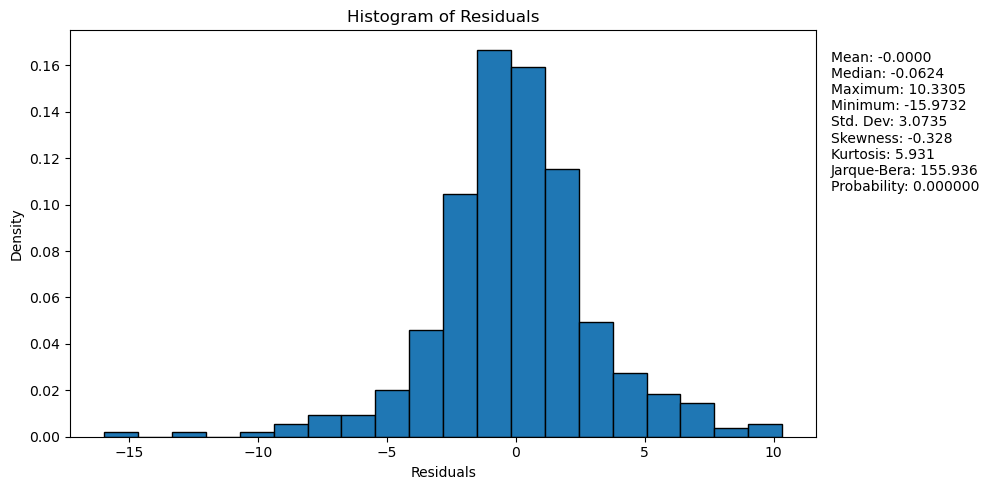

In [41]:
residuals = model.resid
jb_stat, jb_pvalue, skew, kurtosis = jarque_bera(residuals)

plt.figure(figsize=(10,5))

plt.hist(residuals, bins=20, density=True, edgecolor="black")
plt.title("Histogram of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Density")

stats_text = (f"Mean: {residuals.mean():.4f}\n"
              f"Median: {residuals.median():.4f}\n"
              f"Maximum: {residuals.max():.4f}\n"
              f"Minimum: {residuals.min():.4f}\n"
              f"Std. Dev: {residuals.std():.4f}\n"
              f"Skewness: {skew:.3f}\n"
              f"Kurtosis: {kurtosis:.3f}\n"
              f"Jarque-Bera: {jb_stat:.3f}\n"
              f"Probability: {jb_pvalue:.6f}\n")

plt.text(1.02, 0.95, stats_text, transform=plt.gca().transAxes, verticalalignment="top")
plt.tight_layout()
plt.show()

**Test Statistic and Distribution**

$$
JB = n \left[\frac{S^2}{6} + \frac{(K-3)^2}{24}\right] \overset{H_0}{\sim}\chi^2_{\alpha, \, 2}
$$

Where:

- $n$ = Number of observations
- $S$ = Skewness
- $K$ = Kurtosis

$$
n = 415
$$

$$
S = -0.328
$$

$$
K = 5.931
$$

$$
JB = 415 \left[\frac{-0.328^2}{6} + \frac{(5.931-3)^2}{24}\right] = 155.936
$$

$$
\chi^2_{critical} = \chi^2_{\alpha, 2} = \chi^2_{0.05, 2} = 5.991
$$

$$
p = 0.000
$$

**Decision Rule**

**P-Value Approach**

- If P-Value < $\alpha \rightarrow$ Reject $H_0$
- If P-Value > $\alpha \rightarrow$ Fail to reject $H_0$

**JB Statistic**

- If JB > $\chi^2_{critical} \rightarrow$ Reject $H_0$
- If JB < $\chi^2_{critical} \rightarrow$ Fail to reject $H_0$

**Conclusion**

From the Jarque-Bera test, the Jarque-Bera test statistic is 155.936 and so is greater than our chi-squared critical of 5.991, and its associated P-Value is less than our significance level of 0.05. Therefore, we reject the null hypothesis at the 5% significance level and can infer that the residuals are not normally distributed. The residuals exhibit negative skewness and excess kurtosis, with a kurtosis of 5.931 in comparison with the normally distributed value of 3, thereby suggesting relatively heavy tails.

***What are the implications of the Jarque-Bera test results on the properties of the OLS Estimator?***

The rejection of the normality of the residuals does not by itself imply that the OLS coefficient estimates are biased or inconsistent. Normality of the error term is not required for OLS in order to estimate the regression coefficients consistently, provided that the other key assumptions such as the zero conditional mean assumption in particular are satisfied. However, the normality assumption is important for the exact finite sample statistical inference and so if the residuals do not have normality, then the usual finite sample t-tests and F-tests may not follow their exact theoretical distributions.

Additionally, since the regression also contains a large sample size of 415 observations, asymptotic theory and Central Limit Theorem make inference less dependent on the normality assumption. Nevertheless, the heavy tailed distribution of the residuals may make the conventional inference less reliable, particularly if there are extreme observations present.

The White test that was carried out previously, identified heteroscedasticity and so heteroscedasticity-robust standard errors should be used for the coefficient inference. While the robust standard errors don't make the residuals normally distributed, they do provide more reliable standard errors, t-statistics, p-values and confidence intervals when the error variance is not constant.

### <a id='toc1_6_7_'></a>[Tests for Multicollinearity](#toc0_)

***Is there evidence of a statistically significant linear relationship between the S&P 500 returns and changes in the VIX? And does this suggest potential multicollinearity between these explanatory variables in the Brent return model?***

Let's examine the relationship between the two explanatory variables and discuss whether multicollinearity may affect the individual significance of their estimated coefficients.

Let's regress S&P 500 returns onto VIX Changes to do a pairwise multicollinearity check.

$$
R_t^{SP500} = \alpha_0 + \alpha_1 \Delta VIX_t + u_t
$$

**Hypothesis**

$$
H_0: \alpha_1 = 0
$$

$$
H_1: \alpha_1 \neq 0
$$

The null hypothesis states that there is no statistically significant relationship

In [42]:
sp500_vix_model = smf.ols(formula="sp500_return ~ vix_change", data=df).fit()
sp500_vix_model_robust = sp500_vix_model.get_robustcov_results(cov_type="HC3")
sp500_vix_model_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           sp500_return   R-squared:                       0.791
Model:                            OLS   Adj. R-squared:                  0.790
Method:                 Least Squares   F-statistic:                     572.4
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.24e-80
Time:                        20:58:42   Log-Likelihood:                -282.40
No. Observations:                 415   AIC:                             568.8
Df Residuals:                     413   BIC:                             576.8
Df Model:                           1                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0600      0.024      2.536      0.012       0.013       0.107
vix_change    -0.4602      0.019    -23.926      0.000      -0.498      -0.422
==============================================================================
Omnibus:                       26.471   Durbin-Watson:                   1.878
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               91.850
Skew:                           0.028   Prob(JB):                     1.13e-20
Kurtosis:                       5.304   Cond. No.                         2.02
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

**Estimated Equation**

$$
\widehat{R}^{SP500}_t = 0.0600 - 0.4602 \Delta VIX_t + e_t
$$

The regression shows a strong negative relationship between the S&P 500 and the changes in VIX, with a 1 point increase in the VIX being associated with a 0.4602 percentage point decrease in the daily S&P 500 return. Additionally, the $R^2$ of the regression shows that 79.1% of the variation in the S&P 500 is explained by the changes in VIX.

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**T-Critical Approach**

If t* doesn't fall into Acceptance Region ($t_{critical}$) $\rightarrow$ Reject $H_0$

If t* falls into Acceptance Region ($t_{critical}$) $\rightarrow$ Fail to Reject $H_0$

**Test Statistic and Distribution**

$$
p = 0.000
$$

$$
t^* = \frac{\hat{\alpha}_1} {SE(\hat{\alpha}_1)} = \frac{-0.4602}{0.019} = -23.926
$$

$$
t_{critical} = \pm 1.960
$$

$$
\alpha = 0.05
$$

*Since the degrees of freedom are 413 which is not listed in the statistical table, the $df = \infty$ row is used as a large sample approximation.*

**Conclusion**

The P-Value is less than 0.05 and the t-test statistic doesn't fall into our t-critical range and so we reject the null hypothesis at the 5% Significance level and there is a statistically significant relationship between S&P 500 returns and changes in the VIX.

#### <a id='toc1_6_7_1_'></a>[Variance Inflation Factor](#toc0_)

Let's investigate whether there is potential multicollinearity between these variables in the model.

First let's do pairwise variance inflation factor (VIF)

$$
R^2 = 0.791
$$

$$
VIF = \frac{1}{1-R^2} = \frac{1}{1-0.791} = 4.78
$$

The pairwise VIF of 4.78 indicates substantial linear dependence between the S&P 500 returns and changes in the VIX. Although it is slightly below the common VIF benchmark of 5, it is however sufficiently high to suggest potential multicollinearity. The full model VIFs will therefore be examined before reaching a final conclusion about multicollinearity in the Brent return model.

**Full Model VIF**

In [43]:
x = df[["escalation", "supply_disruption", "deescalation", "usd_return", "sp500_return", "vix_change",
        "brent_return_l1"]].copy()
x = sm.add_constant(x)

vif_results = pd.DataFrame({"variable": x.columns,
                            "vif": [variance_inflation_factor(x.values, i)
                                    for i in range(x.shape[1])]})
vif_results = (vif_results.query("variable != 'const'").sort_values("vif", ascending=False).reset_index(drop=True))
vif_results

,variable,vif
0,sp500_return,4.893446
1,vix_change,4.876593
2,supply_disruption,1.544768
3,escalation,1.478911
4,deescalation,1.119839
5,usd_return,1.045057
6,brent_return_l1,1.030651


$$
VIF_j
=
\frac{1}{1-R_j^2}
$$

Where:
- $R_j^2$ = Auxiliary regression $R^2$ in which explanatory variable $X_j$ is regressed on all the remaining variables.

**Conclusion**

The full model VIF analysis indicates that multicollinearity is primarily associated with S&P 500 returns and the changes in VIX, which have VIF values of 4.893 and 4.877 respectively. These values are very close to the commonly used threshold of 5 and so suggest a relatively high degree of linear dependence between the two variables while not exceeding the threshold for potentially problematic multicollinearity. All of the other explanatory variables have VIF values close to 1, thereby indicating little evidence of multicollinearity. Therefore, the Brent returns model does not appear to suffer from severe multicollinearity, although the strong relationship between the S&P500 returns and changes in VIX should be considered when interpreting their individual coefficients and statistical significance.

#### <a id='toc1_6_7_2_'></a>[Wald test of S&P 500 and VIX](#toc0_)

Let's investigate whether the S&P 500 returns and the changes in VIX are jointly significant in explaining the daily Brent crude oil returns?

**Hypothesis**

$$
H_0: \beta_5 = \beta_6 = 0
$$

$$
H_1: \text{At least one of } \beta_5, \beta_6 \neq 0
$$

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**Wald Test Statistic**

If $W$ > $\chi^2_{\alpha, q} \rightarrow$ Reject $H_0$

If $W$ ≤ $\chi^2_{\alpha, q} \rightarrow$ Fail to Reject $H_0$

**Wald Test Statistic**

$$
W
=
(\hat{\theta}-\theta_0)'
\left[\operatorname{Var}(\hat{\theta})\right]^{-1}
(\hat{\theta}-\theta_0)
\overset{H_0}{\sim}
\chi_q^2
$$

$$
W
=
\frac{(\hat{\theta}-\theta_0)^2}
{\operatorname{Var}(\hat{\theta})}
\overset{H_0}{\sim}
\chi_{2}^2
$$

With our 5% Significance level:

$$
W
=
\frac{(\hat{\theta}-\theta_0)^2}
{\operatorname{Var}(\hat{\theta})}
\overset{H_0}{\sim}
\chi_{0.05, 2}^2
$$

**Wald Test Hypothetical Likelihood**

![Wald Test Likelihood](Wald_Test_Likelihood.jpg)

***[(Lambert, 2014)](https://www.youtube.com/watch?v=TFKbyXAfr1M)***

If the thetas are far apart then this causes the Wald statistic to be high and if there is a Wald statistic that is a long distance away from zero, then we will reject the null hypothesis.

In [44]:
model_robust.wald_test(["sp500_return = 0", "vix_change = 0"], use_f=False, scalar=True)

<class 'statsmodels.stats.contrast.ContrastResults'>
<Wald test (chi2): statistic=0.8938323422109, p-value=0.6395975227808386, df_denom=2>

$$
W = 0.894
$$

$$
\chi^2_{0.05, 2} = 5.991
$$

$$
p = 0.64
$$

**Conclusion**

From the Wald test, the Wald test statistic is 0.894 and its associated P-Value is 0.64, both of these statistics infer that we fail to reject the null hypothesis at the 5% significance level. Henceforth, there is insufficient statistical evidence to conclude that the S&P 500 returns and change in the VIX are jointly significant in explaining the daily Brent crude oil returns, while holding the other variables in the model constant.

Even though the S&P 500 returns and the changes in VIX did display a strong linear relationship and have VIF values close to 5, the Wald test showcased that they are not jointly significant in explaining Brent returns in the estimated model. This therefore suggests that their strong relationship with each other does not translate into a statistically significant joint contribution to the dependent variable.

***If we assume that there is multicollinearity between the S&P 500 returns and change in the VIX, how would we resolve this?***

**Solution**

In order to solve the problem of multicollinearity between the S&P 500 returns and the changes in the VIX, I would re-estimate the model through a certain process. I would remove the `sp500_return` and re-estimate the model and obtain its $R^2$ value, and will repeat this process on the original model for `vix_change` and retrieve its $R^2$. I will then compare the two $R^2$ values and the model retaining greater explanatory power would be preferred, while the other could be removed to reduce multicollinearity.

**S&P 500 Model**

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 \text{Escalation}_t + \beta_2 \text{SupplyDisruption}_t + \beta_3 \text{Deescalation}_t + \beta_4 r_{t}^{\text{USD}} + \beta_5 r_{t}^{\text{SP500}} + \beta_6 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

**VIX Change Model**

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 \text{Escalation}_t + \beta_2 \text{SupplyDisruption}_t + \beta_3 \text{Deescalation}_t + \beta_4 r_{t}^{\text{USD}} + \beta_5 \Delta \text{VIX}_t + \beta_6 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

In [45]:
sp500_return_model = smf.ols(formula="""brent_return ~ escalation + supply_disruption + deescalation + usd_return + 
                                     sp500_return + brent_return_l1""", data=df).fit()
vix_change_model = smf.ols(formula="""brent_return ~ escalation + supply_disruption + deescalation + usd_return + 
                                   vix_change + brent_return_l1""", data=df).fit()

In [46]:
print("S&P 500 Model")
print(f"R^2:", sp500_return_model.rsquared)
print("\nVIX Change Model")
print(f"R^2:", vix_change_model.rsquared)

S&P 500 Model
R^2: 0.09427146059445046

VIX Change Model
R^2: 0.09279821971478752


**Conclusion**

The model that had the highest $R^2$ was the S&P 500 model with an $R^2$ of 0.094. Therefore, I would keep the S&P 500 returns variable in the model and remove the daily change in VIX from the model.

***What are the consequences of multicollinearity for the OLS Estimator?***

The consequences of multicollinearity for the OLS Estimator is that when there is a presence of imperfect multicollinearity, the OLS Estimators remain unbiased and consistent, provided that the other OLS assumptions are held. However, multicollinearity increases the variances and standard errors of the affected coefficient estimates and so this reduces the precision of the estimates. This also lowers the absolute values of the t-statistics, widens the confidence intervals and can make variables appear individually statistically insignificant even when they are economically relevant variables. Additionally, coefficient estimates may also become unstable and sensitive to small changes in the sample or model specification. Therefore, multicollinearity can make it difficult to determine meaningful conclusion from the model.

### <a id='toc1_6_8_'></a>[Chow Test for a Structural Break](#toc0_)

***Let's implement the Chow test to investigate whether there is a structural break in the parameters of the daily Brent crude oil return model between the pre-conflict and conflict periods.***

We know that the conflict started on the 28th February 2026 and is recorded on its next trading day as 2nd March 2026. Therefore, the 2nd March 2026 would be the structural-break point.

There is one caveat however, the three event dummies are all 0 in the pre-conflict period and therefore those coefficients cannot be estimated in the pre-conflict subsample. So for this Chow test we will use a reduced baseline specification containing the market variables only and test whether these underlying market relationships changed after the conflict began.

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 r_{t}^{\text{USD}} + \beta_2 r_{t}^{\text{SP500}} + \beta_3 \Delta \text{VIX}_t + \beta_4 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

**Hypothesis**

$$
H_0:
\beta_j^{Pre}
=
\beta_j^{Post}
\quad
\text{for all } j
$$

$$
H_1:
\text{At least one parameter differs between the pre-break and post-break periods}
$$

In [47]:
structural_break = pd.Timestamp("2026-03-02")

pre_break = df.loc[df['date'] < structural_break]

post_break = df[df['date'] >= structural_break]

print(f"Pre-break observations:", len(pre_break))
print(f"Post-break observations:", len(post_break))

Pre-break observations: 281
Post-break observations: 134


In [48]:
chow_formula = """brent_return ~ usd_return + sp500_return + vix_change + brent_return_l1"""

In [49]:
pooled_model = smf.ols(formula=chow_formula, data=df).fit()

pre_break_model = smf.ols(formula=chow_formula, data=pre_break).fit()

post_break_model = smf.ols(formula=chow_formula, data=post_break).fit()

In [50]:
rss_pooled = pooled_model.ssr
rss_pre_break = pre_break_model.ssr
rss_post_break = post_break_model.ssr

print(f"Pooled RSS: {rss_pooled:.4f}")
print(f"Pre-break RSS: {rss_pre_break:.4f}")
print(f"Post-break RSS: {rss_post_break:.4f}")

Pooled RSS: 4028.0191
Pre-break RSS: 1053.5311
Post-break RSS: 2329.0378


$$
RSS_{Pooled}
=
\sum_{t=1}^{n}
\hat{\varepsilon}_t^2
$$

$$
RSS_{Pre}
=
\sum
\hat{\varepsilon}_{t,Pre}^{\,2}
$$

$$
RSS_{Post}
=
\sum
\hat{\varepsilon}_{t,Post}^{\,2}
$$

**Test Statistic and Distribution**

$$
F^*
=
\frac{
\left(RSS_P - RSS_1 - RSS_2\right)/k
}{
\left(RSS_1 + RSS_2\right)/(n-2k)
}
\overset{H_0}{\sim}
F_{1-\alpha,\;k,\;n-2k}
$$

$$
RSS_1 = RSS_{Pre}
$$

$$
RSS_2 = RSS_{Post}
$$

$$
F^* = \frac{\left(4028.0191 - 1053.5311 - 2329.0378\right)/5}{\left(1053.5311 + 2329.0378\right)/(415 - 10)} = 15.45614228 = 15.46
$$

$$
F_{critical} = F_{1-\alpha,\;k,\;n-2k} = F_{0.05, \;5, \;405} = 2.21
$$

*Source: Statistical Tables, Appendix D, Table D.3*

*Since the denominator degrees of freedom are 405 which is not exactly listed in the statistical table, the $df_2 = \infty$ row is used as a large sample approximation.*

**Decision Rule**

**F-Critical Approach**

If the F* > $F_{critical} \rightarrow$ Reject $H_0$

If the F* ≤ $F_{critical} \rightarrow$ Fail to reject $H_0$

**Conclusion**

From the Chow test, the F* is greater than the F-Critical and so we reject the null hypothesis at the 5% significance level. Therefore, there is statistically significant evidence of a structural break in the parameters of the Brent crude oil returns model around the 2nd March 2026. This indicates that the relationship between the Brent returns and the explanatory variables in the reduced market model differ between the pre-break and post-break periods. The result of the Chow test is consistent with the change in the behaviour of Brent crude oil returns around the beginning of the conflict period. However, it is important to bear in mind that the Chow test establishes a structural change around a specified date and does not by itself, establish that the conflict caused this change.

***Note:** The classical Chow test is reported as a test of parameter stability. However, since heteroscedasticity was detected in the residuals, its conventional F-test inference should be interpreted with some caution.*

### <a id='toc1_6_9_'></a>[Significance of the conflict on Brent oil returns](#toc0_)

***Holding all other factors equal, let's investigate if there is any evidence that the US-Iran conflict period has an effect on the daily Brent crude oil returns?***

The first step is to create the dummy variable for the conflict period where it is 1 if it is during the conflict and 0 otherwise.

In [51]:
df['conflict'] = (df['date'] >= pd.Timestamp("2026-03-02")).astype(int)

In [52]:
df.head(5)

,date,brent_return,escalation,supply_disruption,deescalation,usd_return,sp500_return,vix_change,brent_return_l1,conflict
0,2025-01-06,0.714335,0,0,0,-0.709716,0.552282,-0.09,0.758868,0
1,2025-01-07,0.734966,0,0,0,0.058331,-1.116600,1.78,0.714335,0
2,2025-01-08,-0.605633,0,0,0,0.361285,0.155911,-0.12,0.734966,0
3,2025-01-10,3.042302,0,0,0,0.608548,-1.553164,1.84,-0.605633,0
4,2025-01-13,3.607655,0,0,0,0.134586,0.157417,-0.35,3.042302,0


**New Estimated Model**

$$
\widehat{R}_t^{Brent} = \hat{\beta}_0 +\hat{\beta}_1 Escalation_t +\hat{\beta}_2 SupplyDisruption_t +\hat{\beta}_3 Deescalation_t +\hat{\beta}_4 r_t^{USD} +\hat{\beta}_5 r_t^{SP500} +\hat{\beta}_6 \Delta VIX_t \\
+\hat{\beta}_7 r_{t-1}^{Brent} +\hat{\beta}_8 Conflict_t + e_t
$$

**Hypothesis**

$$
H_0: \beta_8 = 0
$$

$$
H_1: \beta_8 \neq 0
$$

The null hypothesis states that being in the conflict period has no statistically significant effect on daily Brent crude oil returns.

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**T-Critical Approach**

If t* doesn't fall into Acceptance Region ($t_{critical}$) $\rightarrow$ Reject $H_0$

If t* falls into Acceptance Region ($t_{critical}$) $\rightarrow$ Fail to Reject $H_0$

In [53]:
conflict_model = smf.ols(formula="""brent_return ~ escalation + supply_disruption + deescalation + usd_return +
                                    sp500_return + vix_change + brent_return_l1 + conflict""", data=df).fit()

In [54]:
conflict_model_robust = conflict_model.get_robustcov_results(cov_type="HC3")
conflict_model_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           brent_return   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.077
Method:                 Least Squares   F-statistic:                     3.159
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00175
Time:                        20:58:42   Log-Likelihood:                -1054.2
No. Observations:                 415   AIC:                             2126.
Df Residuals:                     406   BIC:                             2163.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.0753      0.131      0.574      0.566      -0.183       0.333
escalation            2.6271      1.439      1.825      0.069      -0.202       5.457
supply_disruption    -0.9502      2.062     -0.461      0.645      -5.005       3.104
deescalation         -1.3324      2.514     -0.530      0.596      -6.275       3.610
usd_return            2.5015      0.584      4.282      0.000       1.353       3.650
sp500_return         -0.3089      0.403     -0.766      0.444      -1.101       0.483
vix_change           -0.0836      0.251     -0.333      0.739      -0.576       0.409
brent_return_l1       0.0135      0.069      0.197      0.844      -0.121       0.148
conflict              0.1567      0.454      0.345      0.730      -0.736       1.049
==============================================================================
Omnibus:                       43.681   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              163.883
Skew:                          -0.375   Prob(JB):                     2.59e-36
Kurtosis:                       5.986   Cond. No.                         33.0
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

**Test Statistic and Distribution**

$$
p = 0.730
$$

$$
t^* = \frac{\hat{\beta}_8 - \beta_{8}} {SE(\hat{\beta}_8)} = \frac{0.1567}{0.454} = 0.345
$$

$$
t_{critical} = \pm 1.960
$$

$$
\alpha = 0.05
$$

*Since the degrees of freedom are 406 which is not listed in the statistical table, the $df = \infty$ row is used as a large sample approximation.*

**Conclusion**

From the t-test, the t* is 0.345 and its associated P-Value is 0.730, and so we fail to reject the null hypothesis at the 5% significance level. Therefore, there is insufficient statistical evidence to infer that the US-Iran conflict period has a significant effect on daily Brent crude oil returns, while holding all the other variables constant.

### <a id='toc1_6_10_'></a>[Effect of the US Dollar between pre-conflict and conflict periods](#toc0_)

***Does the effect of the US Dollar returns on daily Brent crude oil returns differ between the pre-conflict and conflict periods?***

First, let's create the interaction term

In [55]:
df['usd_conflict'] = (df['usd_return'] * df['conflict'])

**New Estimated Model**

$$
\widehat{R}_t^{Brent} = \hat{\beta}_0 +\hat{\beta}_1 Escalation_t +\hat{\beta}_2 SupplyDisruption_t +\hat{\beta}_3 Deescalation_t +\hat{\beta}_4 r_t^{USD} +\hat{\beta}_5 r_t^{SP500} +\hat{\beta}_6 \Delta VIX_t \\
+\hat{\beta}_7 r_{t-1}^{Brent} +\hat{\beta}_8 Conflict_t + \beta_9 \left(r_t^{USD}\times Conflict_t\right)+ e_t
$$

**Hypothesis**

$$
H_0: \beta_9 = 0
$$

$$
H_1: \beta_9 \neq 0
$$

The null hypothesis states that the effect of the US Dollar returns on daily Brent crude oil returns does not change between the pre-conflict and conflict periods.

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**T-Critical Approach**

If t* doesn't fall into Acceptance Region ($t_{critical}$) $\rightarrow$ Reject $H_0$

If t* falls into Acceptance Region ($t_{critical}$) $\rightarrow$ Fail to Reject $H_0$

In [56]:
usd_conflict_model = smf.ols(formula="""brent_return ~ escalation + supply_disruption + deescalation + usd_return + 
                                        sp500_return + vix_change + brent_return_l1 + conflict + usd_conflict""", 
                                        data=df).fit()

In [57]:
usd_conflict_model_robust = usd_conflict_model.get_robustcov_results(cov_type="HC3")
usd_conflict_model_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           brent_return   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     4.047
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.54e-05
Time:                        20:58:43   Log-Likelihood:                -1035.0
No. Observations:                 415   AIC:                             2090.
Df Residuals:                     405   BIC:                             2130.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.0034      0.123      0.028      0.978      -0.238       0.244
escalation            2.3636      1.379      1.714      0.087      -0.347       5.074
supply_disruption    -1.2222      2.137     -0.572      0.568      -5.423       2.978
deescalation         -2.0170      2.686     -0.751      0.453      -7.296       3.262
usd_return            0.6335      0.560      1.131      0.259      -0.468       1.735
sp500_return         -0.1261      0.372     -0.339      0.735      -0.856       0.604
vix_change           -0.0690      0.223     -0.310      0.757      -0.507       0.369
brent_return_l1       0.0314      0.066      0.474      0.636      -0.099       0.162
conflict              0.2654      0.433      0.613      0.540      -0.586       1.116
usd_conflict          6.7427      1.511      4.461      0.000       3.772       9.714
==============================================================================
Omnibus:                       40.704   Durbin-Watson:                   2.033
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.783
Skew:                          -0.333   Prob(JB):                     1.10e-33
Kurtosis:                       5.887   Cond. No.                         33.1
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

**Test Statistic and Distribution**

$$
p = 0.000
$$

$$
t^* = \frac{\hat{\beta}_9 - \beta_{9}} {SE(\hat{\beta}_9)} = \frac{6.7427}{1.511} = 4.461
$$

$$
t_{critical} = \pm 1.960
$$

$$
\alpha = 0.05
$$

*Since the degrees of freedom are 405 which is not listed in the statistical table, the $df = \infty$ row is used as a large sample approximation.*

**Conclusion**

From the t-test on the interaction term between US Dollar returns and Conflict, the t-test statistic is 4.461 and so is greater than the t-critical values acceptance region, therefore we reject the null hypothesis at the 5% significance level. Furthermore, the associated P-Value is 0.000 which is less than 0.05 and so we have additional support to reject the null hypothesis. We can conclude that there is statistically significant evidence that the effect of the US Dollar returns on the daily Brent crude oil returns differs between the pre-conflict and conflict periods.

The interaction terms coefficient of 6.7427 indicates that the relationship between the US Dollar returns and Brent returns became more positive during the conflict period by approximately 6.74 percentage points relative to the pre-conflict period, while holding the other variables constant.

Before the conflict period, a 1 percentage point increase in the US Dollar returns is associated with approximately a 0.63 percentage point increase in daily Brent crude oil returns. However, during the conflict, the conflict dummy is equal to 1 and so the US Dollar effect become equal to US Dollar returns coefficient plus the interaction terms coefficient. Therefore, a 1 percentage point increase in the US Dollar returns during the conflict is associated with approximately 7.38 percentage point increase in the daily Brent crude oil returns, while holding all other variables constant.

### <a id='toc1_6_11_'></a>[Ramsey RESET Test for Misspecification](#toc0_)

Let's test whether the daily Brent crude oil return model is correctly specified using the Ramsey RESET test.

When conducting a Ramsey RESET test, the functional form of the model needs to include the square of the fitted dependent variable, and this is known as quadratic misspecification.

$$
\begin{aligned}
R_t^{Brent}
={}&
\alpha_0
+\alpha_1 Escalation_t
+\alpha_2 SupplyDisruption_t
+\alpha_3 Deescalation_t
+\alpha_4 R_t^{USD}
\\
&+\alpha_5 R_t^{SP500}
+\alpha_6 \Delta VIX_t
+\alpha_7 R_{t-1}^{Brent}
+\alpha_8 \left(\widehat{R}_t^{Brent}\right)^2
+u_t
\end{aligned}
$$

**Hypothesis**

$$
H_0: \alpha_8 = 0 \rightarrow \text{The model is correctly specified}
$$

$$
H_1: \alpha_8 \neq 0 \rightarrow \text{The model is misspecified}
$$

**Manual Auxiliary Regression**

In [58]:
df_reset = df.copy()

df_reset['fitted_brent_return'] = model.fittedvalues
df_reset['fitted_brent_return_sq'] = (df_reset['fitted_brent_return'] ** 2)

reset_auxiliary_model = smf.ols(formula="""brent_return ~ escalation + supply_disruption + deescalation + usd_return + 
                                            sp500_return + vix_change + brent_return_l1 + fitted_brent_return_sq""",
                                            data=df_reset).fit(cov_type="HC3")
reset_auxiliary_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           brent_return   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.077
Method:                 Least Squares   F-statistic:                     2.975
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00300
Time:                        20:58:43   Log-Likelihood:                -1054.3
No. Observations:                 415   AIC:                             2127.
Df Residuals:                     406   BIC:                             2163.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.1441      0.172      0.837      0.403      -0.194       0.482
escalation                 3.0922      2.138      1.446      0.148      -1.099       7.283
supply_disruption         -1.1433      2.226     -0.514      0.608      -5.507       3.220
deescalation              -1.1239      2.560     -0.439      0.661      -6.142       3.894
usd_return                 2.4933      0.602      4.143      0.000       1.314       3.673
sp500_return              -0.3038      0.400     -0.759      0.448      -1.088       0.480
vix_change                -0.0774      0.250     -0.310      0.757      -0.567       0.412
brent_return_l1            0.0146      0.069      0.212      0.832      -0.121       0.150
fitted_brent_return_sq    -0.0382      0.189     -0.202      0.840      -0.408       0.331
==============================================================================
Omnibus:                       40.152   Durbin-Watson:                   2.008
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              153.093
Skew:                          -0.314   Prob(JB):                     5.71e-34
Kurtosis:                       5.908   Cond. No.                         40.0
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

Let's confirm this with the actual Ramsey RESET Python implementation.

In [59]:
reset_test = linear_reset(model, power=2, test_type="fitted", use_f=True, cov_type="HC3")
print(reset_test)

<F test: F=0.041005148348792896, p=0.8396294187871136, df_denom=406, df_num=1>


**Test Statistic and Distribution**

$$
F^* \overset{H_0}{\sim} F_{\alpha, \;q, \;df}
$$

Where:

- $F^*$ = Ramsey RESET test statistic
- $\alpha = 0.05$ = Significance level
- $q = 1$ = Number of restrictions
- $df = 406$ = Denominator degrees of freedom

$$
p = 0.840
$$

$$
F^* = 0.041
$$

$$
F_{critical} = F_{\alpha, \;q, \;df} = F_{0.05, 1, 406} = 3.84
$$

*Source: Statistical Tables, Appendix D, Table D.3*

*Since the denominator degrees of freedom are 406 which is not exactly listed in the statistical table, the $df_2 = \infty$ row is used as a large sample approximation.*

**Decision Rule**

**P-Value Approach**

If the P-Value ≤ $\alpha \rightarrow$ Reject $H_0$

If the P-Value > $\alpha \rightarrow$ Fail to Reject $H_0$

**F-Critical Approach**

If the F* > $F_{critical} \rightarrow$ Reject $H_0$

If the F* ≤ $F_{critical} \rightarrow$ Fail to reject $H_0$

**Conclusion**

From the Ramsey RESET test for misspecification in the model, the F-statistic is 0.041 which is less than the F-critical and so we fail to reject the null hypothesis at the 5% significance level. Additionally, the associated P-Value from the Ramsey RESET Test is 0.840 and so we have further confirmation to fail to reject the null hypothesis. From the test, we can conclude that there is insufficient statistical evidence of functional-form misspecification in the Brent crude oil returns model. In particular, the squared fitted-value term is not statistically significant, thereby suggesting that adding a quadratic nonlinear component does not actually significantly improve the specification of the model.

### <a id='toc1_6_12_'></a>[Final Model Diagnostics](#toc0_)

***Based on the econometric tests conducted above, let's assess the reliability and adequacy of the estimated Brent crude oil returns model.*** 

Here will be discussed any violations of the classical regression assumptions and the measures taken to address these.

This econometric diagnostic analysis first tested the individual significance of the dummy variables escalation, supply disruption and deescalation and found that only escalation was statistically significant and individually relevant in explaining daily Brent returns. The analysis identified heteroscedasticity through the White test, in the regression residuals and so consequently HC3 heteroscedasticity robust standard errors are used for the final coefficient inference. The Breusch-Godfrey test found no evidence of serial correlation up to order two, and so there is no indication that a HAC correction is required. Additionally, the Jarque-Bera test rejects normality in the residuals, however with there being 415 observations, large sample inference is less dependent on the normality assumption.

A regression of the daily S&P 500 returns onto the daily changes in the VIX was done to examine the relationship between them and conduct a pairwise multicollinearity check. A subsequent t-test found that there is a statistically significant relationship between the S&P 500 returns and the changes in VIX. A VIF analysis showcased a high degree of linear dependence between them and their VIF values remaining below 5 and so are not exceeding the threshold for problematic multicollinearity. The Wald test was implemented on the joint significance of the S&P 500 and the changes in VIX, and subsequently found they were not jointly significant in explaining Brent returns. Finally, a $R^2$ comparison of two models, one with the original estimated model having the VIX removed and one with the S&P 500 removed, was illustrated to showcase how to deal with multicollinearity if it was indeed present. It was found that in the case there was multicollinearity, then the S&P 500 would be kept and the changes in the VIX would be removed.

The Chow test indicated that the parameters of the market model changed around the 2nd March 2026, thereby suggesting a structural change between the pre-conflict and conflict periods. However, when the conflict period dummy was tested for its individual significance, it was found to not be statistically significant, henceforth indicating that even simply being within the conflict period is not associated with a significant average shift in daily Brent returns, after controlling for the other variables. In contrast, a significance test of the interaction term USD-Conflict, was found to be statistically significant, thereby suggesting that the relationship between the US Dollar returns and daily Brent returns changed materially during the conflict period. Finally, the Ramsey RESET test provides no evidence of quadratic functional-form misspecification.

**Final Model**

$$
R_{t}^{\text{Brent}} = \beta_0 + \beta_1 \text{Escalation}_t + \beta_2 \text{SupplyDisruption}_t + \beta_3 \text{Deescalation}_t + \beta_4 r_{t}^{\text{USD}} + \beta_5 r_{t}^{\text{SP500}} + \beta_6 \Delta \text{VIX}_t + \beta_7 r_{t-1}^{\text{Brent}} + \varepsilon_t
$$

The baseline model will remain as the final model, with any statistical inference for the coefficients should be conducted using HC3-heteroscedasticity robust standard errors. An extension of the baseline model would be the addition of the conflict period dummy variable and the USD-Conflict interaction term. This extended specification is used as supplementary analysis to examine whether the conflict period is associated with a change in the level of daily Brent returns as well as the relationship between how the US Dollar returns and Brent returns differs between the pre-conflict and conflict periods.

### <a id='toc1_6_13_'></a>[Overall Conclusion](#toc0_)

***What conclusions can be drawn about the relationship between the US-Iran conflict and daily Brent crude oil returns from the econometric analysis?***

In conclusion, the results from the econometric analysis suggest that the relationship between the US-Iran conflict and Brent crude oil returns is more nuanced than a simple conflict-period effect. Individual escalation events are associated with higher Brent returns in the baseline model, whereas the supply disruption and de-escalation events coefficients are not statistically significant. The conflict period dummy variable is also statistically insignificant. Nevertheless, the Chow test did identify a significant structural break around the beginning of the conflict period, while the interaction term analysis showed that the relationship between the US Dollar returns and Brent returns changed significantly during the conflict period. These findings thereby suggest that the conflict may have altered the way in which Brent prices respond to broader market conditions rather than producing a constant increase in Brent returns throughout the entire conflict period.

### <a id='toc1_6_14_'></a>[Policy and Government Use](#toc0_)

***For what purposes could governments and policymakers use the econometric analysis conducted in this study?***

Governments and policymakers could use this econometric analysis for purposes such as policy making, economic planning, financial risk management and decision making. An example of one of these purposes is energy security planning, by understanding how geopolitical escalations and market disruptions are associated with oil price movements which in turn can inform contingency planning for strategic reserves. These oil price movements are in turn related to fiscal planning as the energy price volatility can affect tax receipts, subsidies and public expenditure. Brent crude oil also affects fuel, transport and production costs and so by understanding oil price shocks it can help assess inflationary risks and monetary policy analysis via distinguishing between energy driven inflation shocks and broader demand pressures. The econometric analysis can inform regulators and public institutions about the changing relationships between oil, volatility, equity markets and the dollar when assessing market stress. This analysis collectively provides a comprehensive toolkit for the government and policymakers to analyse, observe, plan and manage these economic and financial measures with regards to Brent crude oil.

### <a id='toc1_6_15_'></a>[Recommendations](#toc0_)

One recommendation made from the results of this econometric analysis is to use dynamic hedging for energy portfolios due to the interaction term revealing that market sensitivity to the US Dollar returns shift significantly during active geopolitical conflict, therefore risk managers should avoid static currency hedges. Traditional cross-asset correlations break down under wartime shocks, thereby requiring dynamic hedging strategies that rebalance exposure the moment an escalation or supply disruption dummy triggers.

Another recommendation is to perform contingency planning for supply chain vulnerabilities, given that military escalations and supply disruptions introduce immediate upward pricing pressures on Brent crude. Thereby, energy dependent sectors and transport operators should incorporate pre-emptive buffer strategies, such as strategic reserve allocation or options-based price caps rather than relying on reactive purchasing during active conflict phases.

The final recommendation from this analysis is to enact macroeconomic and monetary policy vigilance as for central banks and macroeconomic forecasters, the structural shift in commodity pricing means that geopolitical shocks cannot be treated as temporary noise. This is because the conflict driven oil spikes feed swiftly into broader inflation and currency fluctuations and so monetary policymakers should monitor real-time geopolitical risk indicators alongside standard macroeconomic data to calibrate interest rate paths effectively.

### <a id='toc1_6_16_'></a>[Practical Implications](#toc0_)

These practical implications will bridge economic theory with market reality, the empirical findings from this model offer direct, actionable insights for commodity traders, portfolio risk managers and macroeconomic analysts. One such implication is the decoupling effect of the US Dollar and Brent returns, as the traditional cross-asset methodology relies on a negative correlation between the Dollar and crude oil returns. However, with the interaction term being statistically significant, it henceforth demonstrates that during active conflict regimes, this baseline relationship deteriorates or intensifies.

An additional practical implication is to integrate market fear metrics, as has been done so in this model with the short-term equity volatility changes alongside geopolitical dummy variables, this enables the capture of broad market sentiment spillover. Therefore, by incorporating the changes in VIX for example into short-term forecast models, this will enable traders to distinguish between systematic market-wide risk off events and localised supply-chain shocks, in turn allowing for more precise Value-at-Risk positioning during crisis periods.

Furthermore, by isolating binary indicators, the model is able to assign concrete and empirical magnitude to distinct geopolitical events. This brings us to our final implication, the ability for quantitative analysts to utilise the empirical results from the dummy variables to model scenarios. The coefficient estimates from the event dummy variables can be used as foundational inputs for Monte Carlo scenario simulations, thereby enabling real-time automated repricing of Brent futures contracts immediately following headline announcements.

## <a id='toc1_7_'></a>[References](#toc0_)

* Abdallah, N.; Azhari, T. (2026). Yemen's Houthis declare naval blockade against Saudi Arabia. Investing.com, 20 July. Available from https://www.investing.com/news/commodities-news/yemens-houthis-declare-naval-blockade-against-saudi-arabia--statement-4800903 [Accessed 23 September 2026]
* Alashray, E.; Maher, H.; Martina, M. (2026). US renews strikes on Iran after two military personnel were killed by Iranian attack. The Print, 19 July. Available from https://theprint.in/world/us-renews-strikes-on-iran-after-two-military-personnel-were-killed-by-iranian-attack/2990290/ [Accessed 23 September 2026]
* Amiri, F. (2026). In defiant speech, Pezeshkian calls out Trump and says Iran will fight 'until our last breath'. The Associated Press, 23 September. Available from https://apnews.com/article/iran-pezeshkian-united-nations-general-assembly-trump-war-210d432587bb8dc2d7303ca4c8ea67b6 [Accessed 23 September]
* Anna, C. (2026). A timeline of the Iran conflict and talks aimed at ending it. The Associated Press, 12 July. Available from https://apnews.com/article/iran-us-timeline-trump-hormuz-war-ceasefire-04da58cbae991183f8b52ef5bf615963 [Accessed 23 September 2026]
* Blanchard, Christopher M.; Sharp, Jeremy M.; Thomas, Clayton.; Zanotti, Jim. (2026). U.S. Conflict with Iran. Washington: Congress.gov. Available from https://www.congress.gov/crs-product/R48887 [Accessed 23 September 2026].
* Choukeir, J.; Abouhassira, E. (2026). Iran hits Gulf states and Jordan after seventh night of US strikes. The Print, 18 July. Available from https://theprint.in/world/iran-hits-gulf-states-and-jordan-after-seventh-night-of-us-strikes/2990111/ [Accessed 23 September 2026]
* Choukeir, J.; Elwelly, E.; Martina, M. (2026). More Red Sea shipments disrupted as Rubio says Iran not serious about talks. The Print, 22 July. Available from https://theprint.in/world/more-red-sea-shipments-disrupted-as-rubio-says-iran-not-serious-about-talks/2993499/ [Accessed 23 September 2026]
* Lambert, B. (2014). Wald Test – Introduction. YouTube. Available from: https://www.youtube.com/watch?v=TFKbyXAfr1M [Accessed 24th June 2024]. 
* Reuters. (2026). Trump: US will attack Iranian bridge, power plant for every ship targeted in Hormuz. Reuters, 22 July. Available from https://www.reuters.com/world/trump-us-will-attack-iranian-bridge-power-plant-every-ship-targeted-hormuz-2026-07-22/ [Accessed 23 September 2026]
* Schifrin, N.; Barnhart, E. (2026). At UN General Assembly, Iran's president responds to Trump's 'annihilation' threat. PBS News. Available from https://www.pbs.org/newshour/show/at-un-general-assembly-irans-president-responds-to-trumps-annihilation [Accessed 23 September 2026]
* Tan, F.; Verma, N. (2026). Three tankers carrying Saudi crude make U-turns in Red Sea after Houthi warning. Reuters, 21 July. Available from https://www.reuters.com/world/middle-east/two-tankers-carrying-saudi-crude-make-u-turns-red-sea-after-houthi-warning-2026-07-21/ [Accessed 23 September 2026]
* The Times Of Israel. (2026). Iran Guard says ships transiting Hormuz with US backing involved in 'accident'. The Times of Israel, 19 July. Available from https://www.timesofisrael.com/liveblog_entry/iran-guards-says-ships-transiting-hormuz-with-us-backing-involved-in-accident/ [Accessed 23 September 2026]
* Troderman, J; Keyserling, de Alex. (2026). Crude oil and petroleum product prices increased sharply in the first quarter of 2026. EIA, 7 April. Available from https://www.eia.gov/todayinenergy/detail.php?id=67424 [Accessed 21 September 2026]
* U.S. Central Command. (2026). CENTCOM Finishes Latest Wave of Strikes Against Iran. U.S. Central Command. Available from https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4549624/centcom-finishes-latest-wave-of-strikes-against-iran/ [Accessed 23 September 2026]
* U.S. Central Command. (2026). U.S. Concludes 13th Night of Strikes on Iranian Military Targets. U.S. Central Command. Available from https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4554671/us-concludes-13th-night-of-strikes-on-iranian-military-targets/ [Accessed 23 September 2026]
* U.S. Central Command. (2026). U.S. Finishes Latest Strikes Against Iran. U.S. Central Command. Available from https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4550818/us-finishes-latest-strikes-against-iran/ [Accessed 23 September 2026]
* U.S. Central Command. (2026). U.S. Forces Complete 11th Night of Strikes Against Iran. U.S. Central Command. Available from https://www.centcom.mil/MEDIA/PUBLIC-RELEASES/Article/4552008/us-forces-complete-11th-night-of-strikes-against-iran/ [Accessed 23 September 2026]
* U.S. Department Of The Treasury. (2026). Treasury Launches Unprecedented Campaign Against Iranian Regime on Economic D-Day. U.S. DEPARTMENT OF THE TREASURY. Available from https://home.treasury.gov/news/press-releases/sb0613 [Accessed 23 September 2026]


## <a id='toc1_8_'></a>[Appendix](#toc0_)

* **Dataset**

In [60]:
df.head()

,date,brent_return,escalation,supply_disruption,deescalation,usd_return,sp500_return,vix_change,brent_return_l1,conflict,usd_conflict
0,2025-01-06,0.714335,0,0,0,-0.709716,0.552282,-0.09,0.758868,0,-0.0
1,2025-01-07,0.734966,0,0,0,0.058331,-1.116600,1.78,0.714335,0,0.0
2,2025-01-08,-0.605633,0,0,0,0.361285,0.155911,-0.12,0.734966,0,0.0
3,2025-01-10,3.042302,0,0,0,0.608548,-1.553164,1.84,-0.605633,0,0.0
4,2025-01-13,3.607655,0,0,0,0.134586,0.157417,-0.35,3.042302,0,0.0


* **Percentage Points of the *t* Distribution**

*Statistical Tables Appendix D, Table D.2*

![t Distribution](Percentage%20Points%20of%20the%20t%20Distribution.png)

* **Upper Percentage Points of the *F* Distribution**

*Statistical Tables Appendix D, Table D.3*

Note: This is the table I used for the F Critical value and not the whole table with the other degrees of freedom.

![F Distribution](Upper%20Percentage%20Points%20of%20the%20F%20Distribution.png)

* **Upper Percentage Points of the $\chi^2$ Distribution**

*Statistical Tables Appendix D, Table D.4*

![Chi Distribution](Upper%20Percentage%20Points%20of%20the%20Chi%20Distribution.png)

![Chi Distribution Continued](Upper%20Percentage%20Points%20of%20the%20Chi%20Distribution_2.png)

* **Durbin-Watson *d* Statistic: Significance Points of $d_L$ and $d_U$ at 0.05 Level of Significance**

*Statistical Tables Appendix D: Table D.5A*

![Durbin Watson Significance Points](Durbin%20Watson%20Significance%20Points%20of%20dL%20and%20dU.png)